# EDA: E-commerce Fraud Detection

| # | Question | Sub-questions (answered in the cell with the same code) |
|---|---|---|
| **EQ1** | Can the data be trusted, and which fields carry usable signal at initiation? | `[Q1.1]` Is the log complete, duplicate-free and consistent with its documentation? <br> `[Q1.2]` How are amounts distributed, and do types differ? <br> `[Q1.3]` Which observations are artefacts or outliers, and are outliers fraud? <br> `[Q1.4]` Which variables separate fraud, and which are leakage? |
| **EQ2** | How rare is fraud, and where and when does it occur? | `[Q2.1]` How imbalanced is the label, by count and by value? <br> `[Q2.2]` Which transaction types carry fraud? <br> `[Q2.3]` How do fraud counts and rates vary by hour and day, and are rate differences driven by fraud or by volume? |
| **EQ3** | Which patterns observable at initiation separate fraud from legitimate transactions? | `[Q3.1]` How does fraud likelihood vary with amount? <br> `[Q3.2]` Do origin-destination mismatch indicators separate the classes, and which are deployable? <br> `[Q3.3]` Do accounts recur enough for history features, and how concentrated is fraud on destination accounts? |
| **EQ4** | What do the current rule and simple benchmarks achieve on the business KPIs? | `[Q4.1]` Outcome: net fraud cost rate and net financial loss avoided. <br> `[Q4.2]` Review load and ranking quality: alert precision, alerts per step, Precision@k and PR-AUC. |

In [1]:
# ===== [S0] Setup: libraries, configuration, number formatting, helpers =====
import os, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")

# ---------- Configuration ----------
SAMPLE_NROWS    = None        # None = WHOLE dataset. Use 100 only to check syntax.
DATA_PATH       = "/kaggle/input/datasets/rupakroy/online-payments-fraud-detection-dataset/PS_20174392719_1491204439457_log.csv"
FLAG_THRESHOLD  = 200_000     # documented rule (dataset documentation): an attempt to TRANSFER more than 200,000 in one transaction
MODEL_TYPES     = ["TRANSFER", "CASH_OUT"]   # types in which fraud occurs (verified in [Q2.2])
P_CLIP          = 0.99        # original-scale amount charts are drawn up to this percentile
TOL             = 0.01        # tolerance for balance-identity checks
FPR_GUARDRAIL   = 0.0151      # framing-document reference: global e-commerce false-positive rate (1.51%), measured BY VALUE
ADDITIONAL_COST = 0.0         # KPI terms "fee or margin lost on false declines" and "review cost": not recorded in PaySim -> 0 by design
K_VALUES        = [100, 1_000]   # Precision@k; k = number of alerts of the current rule (16 in the data) is added automatically in [Q4.3]
DOC_STEPS, DOC_DAYS_STATED = 744, 30   # as written in the dataset documentation ("Total steps 744 (30 days simulation)")
SPLIT_STEPS     = (504, 624)  # PROPOSED time-ordered windows: train = steps 1-504 (days 1-21), validation = 505-624 (days 22-26), test = 625-end (days 27-31)
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./working"
for sub in ("tables", "figures"):
    os.makedirs(f"{OUT_DIR}/{sub}", exist_ok=True)

# ---------- Number formatting: never scientific notation ----------
np.set_printoptions(suppress=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", "{:,.2f}".format)      # safety net for any unformatted float

def sdiv(a, b):
    """Safe division: NaN instead of an error when the denominator is 0."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    r = np.divide(a, b, out=np.full(np.broadcast(a, b).shape, np.nan), where=(b != 0))
    return float(r) if r.ndim == 0 else r

def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion k/n (stable for rare events and small n)."""
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n; d = 1 + z ** 2 / n
        c = (p + z ** 2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - h, c + h

def psi_counts(e, a):
    """Population stability index between two count vectors (reference e, new a). < 0.10 stable, > 0.25 large shift."""
    e, a = np.asarray(e, dtype=float), np.asarray(a, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        e, a = np.clip(e / e.sum(), 1e-6, None), np.clip(a / a.sum(), 1e-6, None)
        return float(np.sum((a - e) * np.log(a / e)))

def psi(base, new, inner_edges):
    k = len(inner_edges) + 1
    return psi_counts(np.bincount(np.digitize(base, inner_edges), minlength=k), np.bincount(np.digitize(new, inner_edges), minlength=k))

def _fmt_col(s, decimals, as_pct):
    if as_pct:
        return s.map(lambda v: "" if pd.isna(v) else f"{v:,.2f}%")             # percentages: 2 decimals
    if pd.api.types.is_bool_dtype(s) or not pd.api.types.is_numeric_dtype(s):
        return s.astype(str)
    if pd.api.types.is_integer_dtype(s):
        return s.map(lambda v: f"{v:,}")
    whole = bool(s.dropna().mod(1).eq(0).all() and s.abs().max() < 1e15)       # integer-valued floats print without decimals
    return s.map(lambda v: "" if pd.isna(v) else (f"{v:,.0f}" if whole else f"{v:,.{decimals}f}"))

def format_table(df, decimals=2, pct=None):
    """String-formatted copy: '*_pct' columns -> '96.22%', counts -> '1,234', amounts -> '1,234.57'."""
    cols = [c for c in df.columns if str(c).endswith("_pct")] if pct is None else (list(df.columns) if pct == "all" else pct)
    return pd.DataFrame({c: _fmt_col(df[c], decimals, c in cols) for c in df.columns}, index=df.index)

TEX_MAP = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_", "{": r"\{", "}": r"\}"}
def tex_escape(s):
    return "".join(TEX_MAP.get(ch, ch) for ch in str(s))

def save_tex(f, name, index=True):
    d = f.rename_axis(f.index.name or "").reset_index() if index else f
    lines = [r"\begin{tabular}{" + ("l" + "r" * (d.shape[1] - 1) if index else "r" * d.shape[1]) + "}", r"\toprule",
             " & ".join(tex_escape(c) for c in d.columns) + r" \\", r"\midrule"]
    lines += [" & ".join(tex_escape(v) for v in row) + r" \\" for row in d.itertuples(index=False)]
    lines += [r"\bottomrule", r"\end{tabular}"]
    with open(f"{OUT_DIR}/tables/{name}.tex", "w") as fh:
        fh.write("\n".join(lines) + "\n")

def show(df, name, decimals=2, pct=None, transpose=False, index=True):
    """Display a formatted table; save the raw values (.csv) and the formatted table (.tex)."""
    f = format_table(df, decimals, pct)
    f = f.T if transpose else f
    display(f if index else f.reset_index(drop=True))
    df.to_csv(f"{OUT_DIR}/tables/{name}.csv", index=index)
    save_tex(f, name, index)

# ---------- Plotting helpers: one chart per figure, full-number axes ----------
BLUE, ORANGE, GREY, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#8b8a85", "#1baf7a", "#e87ba4"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True, "figure.facecolor": "white"})
PLAIN   = FuncFormatter(lambda v, _: f"{v:,.0f}" if (v == 0 or abs(v) >= 1) else np.format_float_positional(v, trim="-"))
PCT     = FuncFormatter(lambda v, _: f"{v:,.2f}%")
PCT_LOG = FuncFormatter(lambda v, _: (f"{v:,.4f}".rstrip("0").rstrip(".") if v != 0 else "0") + "%")
FMT = {"plain": {False: PLAIN, True: PLAIN}, "pct": {False: PCT, True: PCT_LOG}}
FIGS = []

def finish(fig, ax, fid, slug, title, xlabel="", ylabel="", scale="single version",
           logx=False, logy=False, xfmt=None, yfmt=None, legend=False):
    ax.set_title("\n".join(textwrap.wrap(title, 68)), loc="left", fontsize=14, fontweight="bold")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    for axis, fm, is_log in ((ax.xaxis, xfmt, logx), (ax.yaxis, yfmt, logy)):
        if fm:
            axis.set_major_formatter(FMT[fm][is_log])
            if is_log: axis.set_minor_formatter(NullFormatter())
    if legend: ax.legend(frameon=False)
    fig.tight_layout()
    fname = f"{fid}_{slug}.png"
    fig.savefig(f"{OUT_DIR}/figures/{fname}", dpi=200, bbox_inches="tight", facecolor="white")
    FIGS.append({"figure": fid, "scale": scale, "title": title, "file": fname})
    plt.show(); plt.close(fig)

def scaled_pair(fid, slug, title, draw, xlabel, ylabel, log_axis, xfmt=None, yfmt=None, legend=False, orig_note="", figsize=(9, 5)):
    """[SCALED PAIR] Draw ONE chart twice: version a = original values, version b = `log_axis` on a log scale.
    `draw(ax, log)` plots the data; `log` tells it which version is being drawn."""
    for suffix, log in (("a", False), ("b", True)):
        fig, ax = plt.subplots(figsize=figsize)
        draw(ax, log)
        tag = "log scale" if log else f"original scale{orig_note}"
        finish(fig, ax, f"{fid}{suffix}", f"{slug}_{'log' if log else 'original'}", f"{title} ({tag})",
               xlabel + (" (log scale)" if log and log_axis == "x" else ""), ylabel + (" (log scale)" if log and log_axis == "y" else ""),
               scale="log version" if log else "original version", logx=log and log_axis == "x", logy=log and log_axis == "y",
               xfmt=xfmt, yfmt=yfmt, legend=legend)

def bar_chart(fid, slug, title, labels, values, xlabel, ylabel, color=BLUE, pct=False, rotate=0,
              annotate=True, horizontal=False, figsize=(9, 5)):
    """Single-version bar chart with direct value labels (full numbers / 2-decimal percentages)."""
    fig, ax = plt.subplots(figsize=figsize)
    labels, values = [str(l) for l in labels], np.asarray(values, dtype=float)
    bars = ax.barh(labels, values, color=color) if horizontal else ax.bar(labels, values, color=color)
    if horizontal: ax.invert_yaxis()
    if annotate:
        for r, v in zip(bars, values):
            if np.isnan(v): continue
            txt = f"{v:,.2f}%" if pct else f"{v:,.0f}"
            if horizontal: ax.annotate(txt, (r.get_width(), r.get_y() + r.get_height() / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=10)
            else:          ax.annotate(txt, (r.get_x() + r.get_width() / 2, r.get_height()), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10)
    if rotate: plt.setp(ax.get_xticklabels(), rotation=rotate, ha="right")
    vfmt = "pct" if pct else "plain"        # the value axis is x for horizontal bars, y otherwise
    finish(fig, ax, fid, slug, title, xlabel, ylabel, xfmt=vfmt if horizontal else None, yfmt=None if horizontal else vfmt)

HANDOFF = []     # headline facts for the report / next stages, assembled in [H1]
def note(item, value, where):
    HANDOFF.append({"item": item, "value": value, "where_in_notebook": where})

## EQ1: Can the data be trusted, and which fields carry usable signal at initiation?

In [2]:
# ===== [Q1.1] Is the log complete, duplicate-free and consistent with its documentation? =====
TYPES = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]
EXPECTED = ["step", "type", "amount", "nameOrig", "oldbalanceOrg", "newbalanceOrig",
            "nameDest", "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"]
raw = pd.read_csv(DATA_PATH, nrows=SAMPLE_NROWS)
assert list(raw.columns) == EXPECTED, f"Unexpected columns: {list(raw.columns)}"
raw["type"] = raw["type"].astype(str).str.strip().str.upper().str.replace("-", "_", regex=False)
assert raw["type"].isin(TYPES).all(), "Unknown transaction type present"
if not raw["step"].is_monotonic_increasing:                 # file order is used as time order below (PaySim has no order WITHIN a step)
    raw = raw.sort_values("step", kind="stable").reset_index(drop=True)
N = len(raw)

# ---- Integrity checks (computed on the raw log before identifiers are replaced by codes) ----
BAL = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
integrity = pd.DataFrame({
    "rows": [N], "null_cells": [int(raw.isna().sum().sum())], "fully_duplicated_rows": [int(raw.duplicated().sum())],
    "negative_amount_or_balance_cells": [int((raw[BAL] < 0).sum().sum())],
    "sender_names_not_starting_with_C": [int((~raw["nameOrig"].str.startswith("C")).sum())],
    "distinct_sender_accounts": [int(raw["nameOrig"].nunique())], "distinct_destination_accounts": [int(raw["nameDest"].nunique())]},
    index=["PaySim log"])
show(integrity, "Q1_1_integrity")

# ---- Time span: observed steps versus the dataset documentation ("Total steps 744 (30 days simulation)") ----
steps_seen = np.sort(raw["step"].unique()); first_s, last_s = int(steps_seen[0]), int(steps_seen[-1])
last_day = (last_s - 1) // 24 + 1
timespan = pd.DataFrame({
    "documented_total_steps": [DOC_STEPS], "documented_days": [DOC_DAYS_STATED], "days_implied_by_documented_steps": [DOC_STEPS / 24],
    "first_step": [first_s], "last_step": [last_s], "distinct_steps": [int(steps_seen.size)],
    "missing_steps_inside_range": [int(last_s - first_s + 1 - steps_seen.size)],
    "documented_steps_not_observed": [DOC_STEPS - int(steps_seen.size)],
    "days_spanned_by_last_step": [last_s / 24], "last_day": [last_day],
    "steps_observed_in_last_day": [int((steps_seen > 24 * (last_day - 1)).sum())]}, index=["PaySim log"])
show(timespan, "Q1_1_time_span", transpose=True)

# ---- Documented fraud scenario: does the destination of a fraudulent TRANSFER later appear as the sender of a CASH_OUT? ----
_co_first = raw.loc[raw["type"] == "CASH_OUT"].groupby("nameOrig")["step"].min()
_ft = raw.loc[(raw["type"] == "TRANSFER") & (raw["isFraud"] == 1), ["nameDest", "step"]]
_hit = int((_ft["nameDest"].map(_co_first) >= _ft["step"]).sum())          # "at or after": the order inside one step is unknown
chain = pd.DataFrame({"fraudulent_transfers": [len(_ft)], "destination_cashes_out_at_or_after_the_transfer_step": [_hit],
                      "share_pct": [100 * sdiv(_hit, len(_ft))]}, index=["transfer-then-cash-out chain"])
del _co_first, _ft

# ---- Account identifiers -> small numeric summaries (the long strings are then dropped to save memory) ----
orig_codes, _ = pd.factorize(raw["nameOrig"])
dest_codes, _ = pd.factorize(raw["nameDest"])
dest_class = raw["nameDest"].str[0].to_numpy()
assert set(np.unique(dest_class)) <= {"C", "M"}, "Unexpected destination prefix"
prior_dest = pd.Series(dest_codes).groupby(dest_codes).cumcount().to_numpy().astype("int32")   # earlier rows with the same destination
orig_counts = np.bincount(orig_codes)                                                          # rows per sender account
cust_dest_counts = np.bincount(dest_codes)[np.unique(dest_codes[dest_class == "C"])]           # rows per customer destination

df = pd.DataFrame({
    "step": raw["step"].astype("int32"),
    "type": pd.Categorical(raw["type"], categories=TYPES),
    "dest_class": pd.Categorical(dest_class, categories=["C", "M"]),
    "amount": raw["amount"], "oldbalanceOrg": raw["oldbalanceOrg"], "newbalanceOrig": raw["newbalanceOrig"],
    "oldbalanceDest": raw["oldbalanceDest"], "newbalanceDest": raw["newbalanceDest"],
    "isFraud": raw["isFraud"].astype("int8"), "isFlaggedFraud": raw["isFlaggedFraud"].astype("int8"),
})
df["hour"] = ((df["step"] - 1) % 24).astype("int8")          # hour of day (0-23); step 1 is taken as hour 0
df["day"]  = ((df["step"] - 1) // 24 + 1).astype("int8")     # day of the month (1-31); the last day is partial
df["week"] = ((df["step"] - 1) // 168 + 1).astype("int8")    # 7-day window (week 5 is partial)
df["window"] = pd.Categorical(np.select([df["step"] <= SPLIT_STEPS[0], df["step"] <= SPLIT_STEPS[1]], ["train", "validation"], default="test"),
                              categories=["train", "validation", "test"])      # proposed time-ordered split, examined in [Q2.4]
df["fraud_value"] = df["amount"] * df["isFraud"]
df["in_scope"] = df["type"].isin(MODEL_TYPES)
df["dest_first_seen"] = prior_dest == 0                      # deployable: depends on earlier rows only (order inside a step = file order)
df["prior_dest"] = prior_dest
_y = df["isFraud"].to_numpy().astype("int64")
df["dest_prior_fraud"] = (pd.Series(_y).groupby(dest_codes).cumsum().to_numpy() - _y) > 0   # an EARLIER row sent fraud to this destination (label assumed known at once: optimistic)
# Diagnostic indicators built from balance fields (leakage evidence only, never candidate features)
exp_orig = np.where(df["type"] == "CASH_IN", df["oldbalanceOrg"] + df["amount"], df["oldbalanceOrg"] - df["amount"])
df["orig_emptied"]         = (df["oldbalanceOrg"] > 0) & (df["newbalanceOrig"] == 0)
df["dest_unchanged_zero"]  = (df["oldbalanceDest"] == 0) & (df["newbalanceDest"] == 0) & (df["amount"] > 0) & (dest_class == "C")
df["orig_identity_fails"]  = (df["newbalanceOrig"] - exp_orig).abs() > TOL
df["dest_identity_fails"]  = (df["newbalanceDest"] - (df["oldbalanceDest"] + df["amount"])).abs() > TOL

DEST = dest_codes.astype("int32")                            # destination account code of every row (same row order as df)
# del rig_codes, dest_codes, exp_orig, _y

# Reusable arrays and totals
AMT = df["amount"].to_numpy(); Y = df["isFraud"].to_numpy().astype(bool); IN_SC = df["in_scope"].to_numpy()
TOTAL_FRAUD_N = int(Y.sum()); TOTAL_FRAUD_V = float(AMT[Y].sum()); LEGIT_N = int((~Y).sum()); LEGIT_V = float(AMT[~Y].sum())
TPV = float(AMT.sum()); N_STEPS_OBS = int(df["step"].nunique())
SC = df[df["in_scope"]].copy()          # modelling population: TRANSFER + CASH_OUT (row labels = positions in df and DEST)

def segment_table(d, by):
    """Transactions, fraud cases/value, fraud rates (with 95% Wilson interval) for each level of `by`."""
    g = d.groupby(by, observed=True)
    t = pd.DataFrame({"transactions": g.size(), "fraud_cases": g["isFraud"].sum(),
                      "total_value": g["amount"].sum(), "fraud_value": g["fraud_value"].sum()})
    t["fraud_rate_pct"] = 100 * sdiv(t["fraud_cases"], t["transactions"])
    lo, hi = wilson(t["fraud_cases"], t["transactions"])
    t["fraud_rate_ci_low_pct"], t["fraud_rate_ci_high_pct"] = 100 * lo, 100 * hi
    t["fraud_value_rate_pct"]      = 100 * sdiv(t["fraud_value"], t["total_value"])
    t["share_of_fraud_cases_pct"]  = 100 * sdiv(t["fraud_cases"], t["fraud_cases"].sum())
    t["share_of_fraud_value_pct"]  = 100 * sdiv(t["fraud_value"], t["fraud_value"].sum())
    return t

snapshot = pd.DataFrame({"rows": [N], "fraud_cases": [TOTAL_FRAUD_N], "fraud_value": [TOTAL_FRAUD_V], "total_payment_value": [TPV],
                         "single_use_sender_accounts_pct": [100 * sdiv((orig_counts == 1).sum(), orig_counts.size)]}, index=["PaySim log"])
show(snapshot, "Q1_1_dataset_snapshot")

,rows,null_cells,fully_duplicated_rows,negative_amount_or_balance_cells,sender_names_not_starting_with_C,distinct_sender_accounts,distinct_destination_accounts
PaySim log,"6,362,620",0,0,0,0,"6,353,307","2,722,362"


,PaySim log
documented_total_steps,744
documented_days,30
days_implied_by_documented_steps,31
first_step,1
last_step,743
distinct_steps,743
missing_steps_inside_range,0
documented_steps_not_observed,1
days_spanned_by_last_step,30.96
last_day,31


,rows,fraud_cases,fraud_value,total_payment_value,single_use_sender_accounts_pct
PaySim log,"6,362,620","8,213","12,056,415,427.84","1,144,392,944,759.77",99.85%


In [3]:
ROLE = {"step": "time index (hours)", "type": "categorical feature", "amount": "numeric feature",
        "nameOrig": "ID (sender account)", "oldbalanceOrg": "numeric feature", "newbalanceOrig": "numeric feature",
        "nameDest": "ID (recipient account)", "oldbalanceDest": "numeric feature", "newbalanceDest": "numeric feature",
        "isFraud": "TARGET (0/1)", "isFlaggedFraud": "rule-engine flag (0/1), not a feature"}
nun = raw.nunique()
structure = pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": nun,
                          "unique_pct": 100 * nun / N, "role": pd.Series(ROLE)})

type_freq = raw["type"].value_counts().rename("n").to_frame()
type_freq["pct"] = 100 * type_freq["n"] / N
type_freq["rare(<1%)"] = np.where(type_freq["pct"] < 1, "YES", "")

dest_cls = pd.Series(dest_class).value_counts().rename("n").to_frame()
dest_cls["pct"] = 100 * dest_cls["n"] / N

parse = {
    "numeric columns stored as numeric": all(pd.api.types.is_numeric_dtype(raw[c]) for c in
        ["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"]),
    "type values with stray whitespace/case": int((raw["type"] != raw["type"].str.strip().str.upper()).sum()),
    "ID values with stray whitespace": int((raw["nameOrig"] != raw["nameOrig"].str.strip()).sum()
                                          + (raw["nameDest"] != raw["nameDest"].str.strip()).sum()),
    "step values that are not whole numbers": int((raw["step"] % 1 != 0).sum()),
}

,count,mean,std,min,p01,p25,median,p75,p99,p99_9,max,skewness,excess_kurtosis,zero_pct
amount,"6,362,620","179,861.90","603,858.23",0,449.47,"13,389.57","74,871.94","208,721.48","1,615,979.47","8,956,797.68","92,445,516.64",30.99,"1,797.96",0.00%
oldbalanceOrg,"6,362,620","833,883.10","2,888,242.67",0,0.00,0.00,"14,208.00","107,315.18","16,027,256.13","26,825,930.20","59,585,040.37",5.25,32.96,33.04%
newbalanceOrig,"6,362,620","855,113.67","2,924,048.50",0,0.00,0.00,0.00,"144,258.41","16,176,160.56","26,971,658.93","49,585,040.37",5.18,32.07,56.73%
oldbalanceDest,"6,362,620","1,100,701.67","3,399,180.11",0,0.00,0.00,"132,705.66","943,036.71","12,371,819.15","34,392,786.79","356,015,889.35",19.92,948.67,42.50%
newbalanceDest,"6,362,620","1,224,996.40","3,674,128.94",0,0.00,0.00,"214,661.44","1,111,909.25","13,137,866.94","39,531,571.97","356,179,278.92",19.35,862.16,38.34%


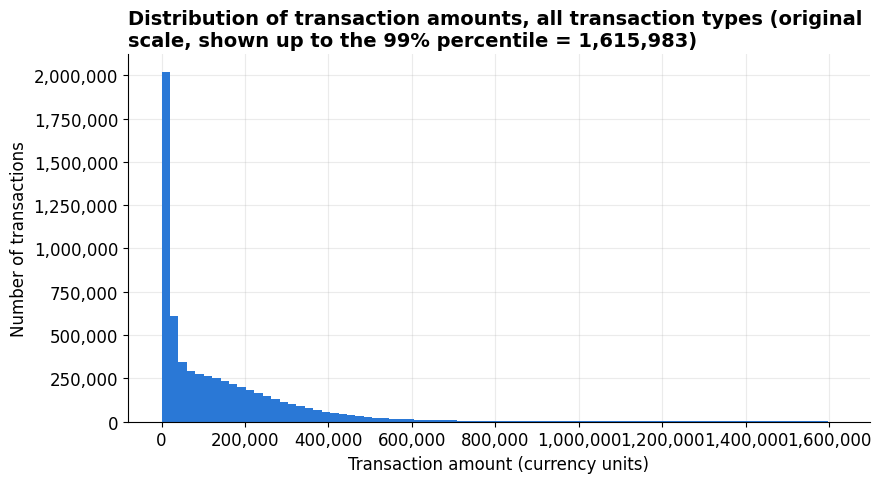

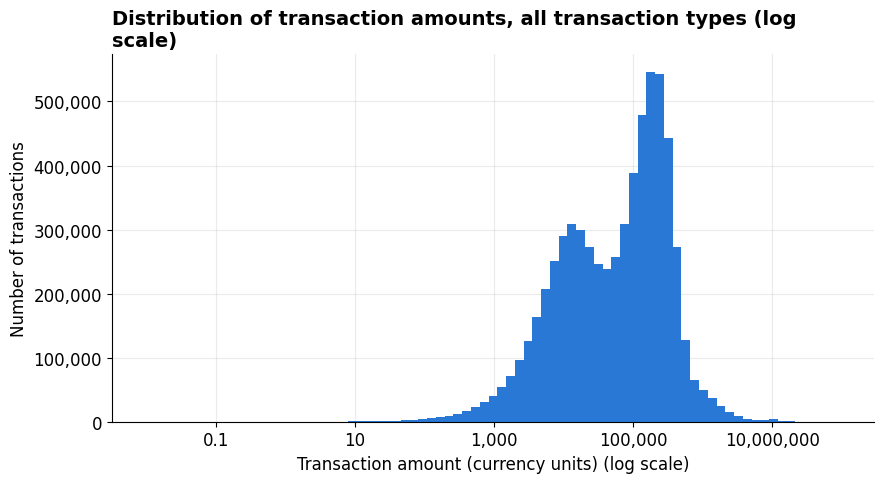

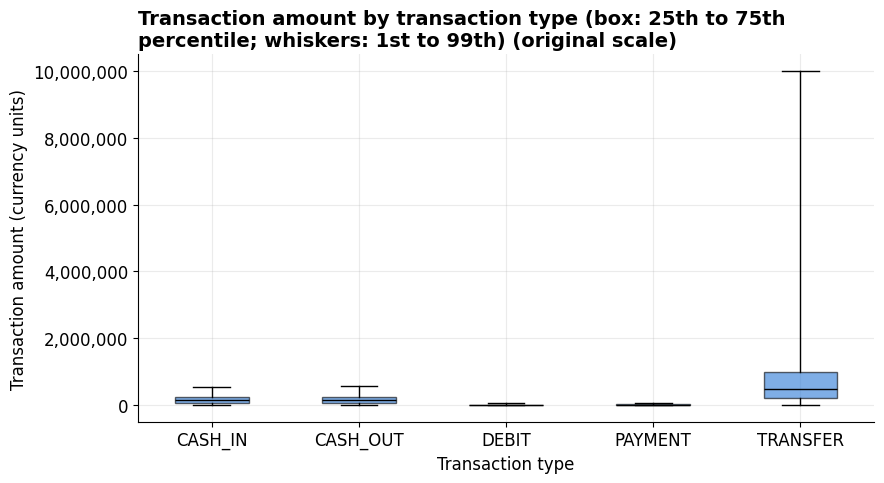

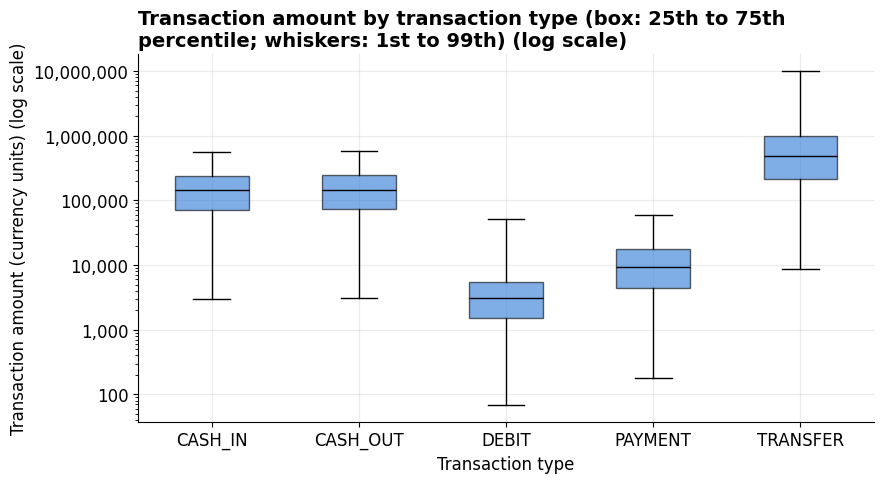

In [4]:
# ===== [Q1.2] How are amounts distributed, and do types differ? =====
NUM = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
desc = (df[NUM].describe(percentiles=[.01, .25, .5, .75, .99, .999]).T
        .rename(columns={"1%": "p01", "25%": "p25", "50%": "median", "75%": "p75", "99%": "p99", "99.9%": "p99_9"}))
desc["skewness"] = df[NUM].skew(); desc["excess_kurtosis"] = df[NUM].kurt(); desc["zero_pct"] = (df[NUM] == 0).mean() * 100
show(desc, "Q1_2_numeric_summary")

pos_df = df.loc[df["amount"] > 0, ["type", "amount"]]       # zero amounts cannot be drawn on a log axis
pos = pos_df["amount"].to_numpy()
clip = float(np.quantile(pos, P_CLIP)) if pos.size else 1.0

def draw_amount_hist(ax, log):
    if not pos.size: return
    if log: ax.hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 80), color=BLUE)
    else:   ax.hist(pos[pos <= clip], bins=80, color=BLUE)

# >>> SCALED PAIR: F01a = original values (x-axis cut at the 99th percentile), F01b = log scale <<<
scaled_pair("F01", "amount_distribution", "Distribution of transaction amounts, all transaction types", draw_amount_hist,
            xlabel="Transaction amount (currency units)", ylabel="Number of transactions", log_axis="x",
            xfmt="plain", yfmt="plain", orig_note=f", shown up to the {P_CLIP:.0%} percentile = {clip:,.0f}")

box_stats = []
for t, s in pos_df.groupby("type", observed=True)["amount"]:
    q = np.quantile(s.to_numpy(), [.01, .25, .5, .75, .99])
    box_stats.append(dict(label=t, whislo=q[0], q1=q[1], med=q[2], q3=q[3], whishi=q[4], fliers=[]))

def draw_amount_box(ax, log):
    if box_stats:
        ax.bxp(box_stats, showfliers=False, patch_artist=True, boxprops=dict(facecolor=BLUE, alpha=.6), medianprops=dict(color="black"))

# >>> SCALED PAIR: F02a = original values, F02b = log scale (y-axis). Box = 25th-75th percentile, whiskers = 1st-99th percentile <<<
scaled_pair("F02", "amount_by_type", "Transaction amount by transaction type (box: 25th to 75th percentile; whiskers: 1st to 99th)",
            draw_amount_box, xlabel="Transaction type", ylabel="Transaction amount (currency units)", log_axis="y", yfmt="plain")

In [5]:
# ===== [Q1.3] Which observations are artefacts or outliers, and are outliers fraud? =====
g = df.groupby("type", observed=True)["amount"]
ot = pd.DataFrame({"transactions": g.size(), "median": g.median(), "p99": g.quantile(.99), "max": g.max(),
                   "q1": g.quantile(.25), "q3": g.quantile(.75)})
ot["upper_fence_3xIQR"] = ot["q3"] + 3 * (ot["q3"] - ot["q1"])
fence = ot["upper_fence_3xIQR"].reindex(TYPES).to_numpy()[df["type"].cat.codes.to_numpy()]
df["is_amount_outlier"] = AMT > fence
ot["outliers"] = df.groupby("type", observed=True)["is_amount_outlier"].sum()
ot["outlier_pct"] = 100 * sdiv(ot["outliers"], ot["transactions"])
ot["fraud_rate_in_outliers_pct"]     = 100 * df[df["is_amount_outlier"]].groupby("type", observed=True)["isFraud"].mean()
ot["fraud_rate_in_non_outliers_pct"] = 100 * df[~df["is_amount_outlier"]].groupby("type", observed=True)["isFraud"].mean()
show(ot, "Q1_3_outliers_by_type")

fmax = float(df.loc[df["isFraud"] == 1, "amount"].max()) if TOTAL_FRAUD_N else np.nan
cap_check = pd.DataFrame({"max_fraud_amount": [fmax], "fraud_rows_at_max": [int(((df["amount"] == fmax) & (df["isFraud"] == 1)).sum())],
                          "legitimate_rows_at_same_amount": [int(((df["amount"] == fmax) & (df["isFraud"] == 0)).sum())],
                          "legitimate_rows_above_max_fraud_amount": [int(((df["amount"] > fmax) & (df["isFraud"] == 0)).sum())],
                          "zero_amount_rows": [int((df["amount"] == 0).sum())],
                          "zero_amount_fraud_rows": [int(((df["amount"] == 0) & (df["isFraud"] == 1)).sum())]}, index=["value"])
show(cap_check, "Q1_3_amount_cap_and_zero", transpose=True)

,transactions,median,p99,max,q1,q3,upper_fence_3xIQR,outliers,outlier_pct,fraud_rate_in_outliers_pct,fraud_rate_in_non_outliers_pct
type,,,,,,,,,,,
CASH_IN,"1,399,284","143,427.71","550,870.86","1,915,267.90","70,510.18","239,899.09","748,065.80","1,097",0.08%,0.00%,0.00%
CASH_OUT,"2,237,500","147,072.18","579,654.07","10,000,000.00","72,669.65","246,539.48","768,148.96","3,609",0.16%,43.56%,0.11%
DEBIT,"41,432","3,048.99","50,817.98","569,077.51","1,500.18","5,479.18","17,416.16","1,645",3.97%,0.00%,0.00%
PAYMENT,"2,151,495","9,482.19","59,500.11","238,637.98","4,383.82","17,561.22","57,093.42","25,692",1.19%,0.00%,0.00%
TRANSFER,"532,909","486,308.39","10,000,000.00","92,445,516.64","215,905.35","974,958.00","3,252,115.95","19,488",3.66%,2.84%,0.69%


,value
max_fraud_amount,"10,000,000"
fraud_rows_at_max,287
legitimate_rows_at_same_amount,"2,920"
legitimate_rows_above_max_fraud_amount,"2,443"
zero_amount_rows,16
zero_amount_fraud_rows,16


In [6]:
# ===== [Q1.4] Which variable separate fraud, and which are leakage? =====
NUMX = ["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
corr_tab = pd.DataFrame({"pearson": df[NUMX].corrwith(df["isFraud"]), "spearman": df[NUMX].rank().corrwith(df["isFraud"].rank())})
show(corr_tab, "Q1_4_correlation_with_fraud", decimals=4)

def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    if min(ct.shape) < 2: return np.nan
    try: chi2 = chi2_contingency(ct, correction=False)[0]
    except ValueError: return np.nan
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))
cv_tab = pd.DataFrame({"cramers_v_with_isFraud": [cramers_v(df["type"].cat.codes, df["isFraud"]), cramers_v(df["dest_class"].cat.codes, df["isFraud"])]},
                      index=["transaction type", "destination account class"])
show(cv_tab, "Q1_4_cramers_v", decimals=4)

ys = SC["isFraud"].to_numpy()
FEATURES = {   # feature -> (values, available at initiation?)
    "amount": (SC["amount"], "yes"), "step": (SC["step"], "yes"), "hour": (SC["hour"], "yes"),
    "is_transfer (vs CASH_OUT)": (SC["type"] == "TRANSFER", "yes"), "destination_first_seen": (SC["dest_first_seen"], "yes"),
    "oldbalanceOrg": (SC["oldbalanceOrg"], "no: balance field"), "newbalanceOrig": (SC["newbalanceOrig"], "no: balance field"),
    "oldbalanceDest": (SC["oldbalanceDest"], "no: balance field"), "newbalanceDest": (SC["newbalanceDest"], "no: balance field"),
    "origin_emptied": (SC["orig_emptied"], "no: balance field"), "destination_unchanged_zero": (SC["dest_unchanged_zero"], "no: balance field"),
    "origin_identity_fails": (SC["orig_identity_fails"], "no: balance field"), "destination_identity_fails": (SC["dest_identity_fails"], "no: balance field")}
auc_rows = []
for name, (x, ok) in FEATURES.items():
    a = roc_auc_score(ys, x.astype(float)) if 0 < ys.sum() < len(ys) else np.nan
    auc_rows.append({"feature": name, "available_at_initiation": ok, "auc": a, "separation": abs(2 * a - 1)})
auc_tab = pd.DataFrame(auc_rows).set_index("feature").sort_values("separation", ascending=False)
show(auc_tab, "Q1_4_signal_vs_leakage", decimals=4)

,pearson,spearman
step,0.0316,0.0208
amount,0.0767,0.0361
oldbalanceOrg,0.0102,0.0394
newbalanceOrig,-0.0081,-0.0280
oldbalanceDest,-0.0059,-0.0171
newbalanceDest,0.0005,-0.0052


,cramers_v_with_isFraud
transaction type,0.0589
destination account class,0.0257


,available_at_initiation,auc,separation
feature,,,
origin_identity_fails,no: balance field,0.0502,0.8996
oldbalanceOrg,no: balance field,0.9277,0.8553
oldbalanceDest,no: balance field,0.2141,0.5718
origin_emptied,no: balance field,0.7742,0.5483
destination_unchanged_zero,no: balance field,0.7475,0.4949
destination_first_seen,yes,0.7451,0.4901
newbalanceDest,no: balance field,0.2733,0.4533
amount,yes,0.6834,0.3667
destination_identity_fails,no: balance field,0.6696,0.3392


## EQ2: How rare is fraud, and where and when does it occur?

,All transaction types,TRANSFER + CASH_OUT only
transactions,"6,362,620","2,770,409"
fraud_cases,"8,213","8,213"
legitimate_cases,"6,354,407","2,762,196"
fraud_rate_pct,0.13%,0.30%
legitimate_per_fraud,773.70,336.32
total_payment_value,"1,144,392,944,759.77","879,704,982,487.66"
fraud_value,"12,056,415,427.84","12,056,415,427.84"
fraud_loss_rate_pct,1.05%,1.37%


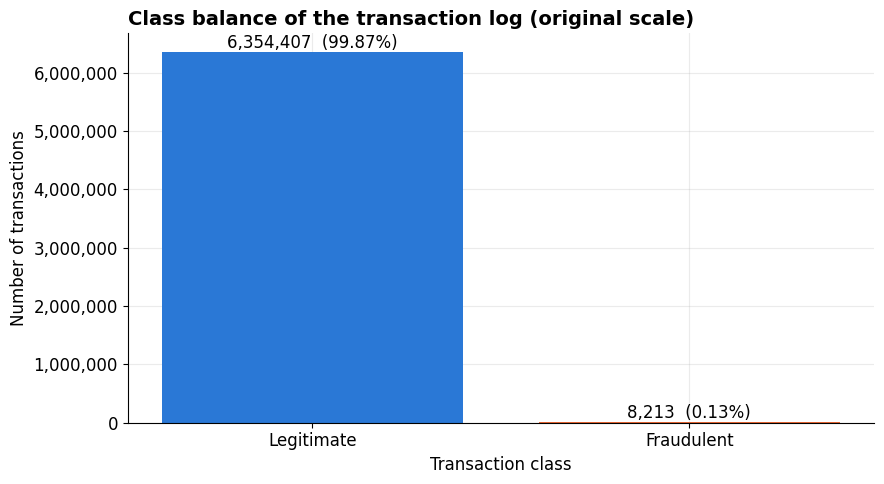

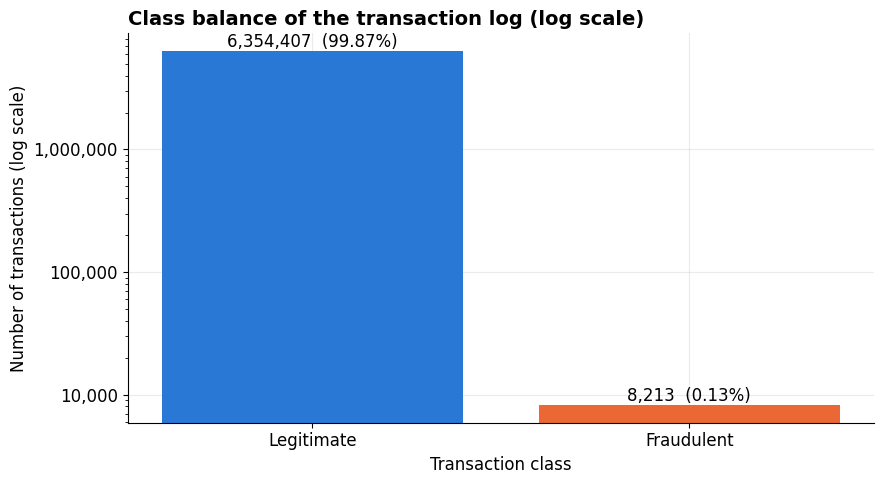

In [7]:
# ===== [Q2.1] How imbalanced is the label, by count and by value? =====
def prevalence(d):
    n, f = len(d), int(d["isFraud"].sum()); tpv, fv = float(d["amount"].sum()), float(d["fraud_value"].sum())
    return {"transactions": n, "fraud_cases": f, "legitimate_cases": n - f, "fraud_rate_pct": 100 * sdiv(f, n),
            "legitimate_per_fraud": sdiv(n - f, f), "total_payment_value": tpv, "fraud_value": fv, "fraud_loss_rate_pct": 100 * sdiv(fv, tpv)}
imb = pd.DataFrame.from_dict({"All transaction types": prevalence(df), "TRANSFER + CASH_OUT only": prevalence(SC)}, orient="index")
show(imb, "Q2_1_class_imbalance", transpose=True)

def draw_class_balance(ax, log):
    counts = [LEGIT_N, TOTAL_FRAUD_N]
    bars = ax.bar(["Legitimate", "Fraudulent"], counts, color=[BLUE, ORANGE])
    for r, c in zip(bars, counts):
        if c > 0: ax.annotate(f"{c:,}  ({100 * c / N:.2f}%)", (r.get_x() + r.get_width() / 2, c), xytext=(0, 3), textcoords="offset points", ha="center")

# >>> SCALED PAIR: F03a = original values (fraud bar is barely visible: that is the point), F03b = log scale <<<
scaled_pair("F03", "class_balance", "Class balance of the transaction log", draw_class_balance,
            xlabel="Transaction class", ylabel="Number of transactions", log_axis="y", yfmt="plain")

,transactions,fraud_cases,total_value,fraud_value,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct,fraud_value_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
type,,,,,,,,,,
CASH_IN,"1,399,284",0,"236,367,391,912.46",0.00,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%
CASH_OUT,"2,237,500","4,116","394,412,995,224.49","5,989,202,243.83",0.18%,0.18%,0.19%,1.52%,50.12%,49.68%
DEBIT,"41,432",0,"227,199,221.28",0.00,0.00%,0.00%,0.01%,0.00%,0.00%,0.00%
PAYMENT,"2,151,495",0,"28,093,371,138.37",0.00,0.00%,-0.00%,0.00%,0.00%,0.00%,0.00%
TRANSFER,"532,909","4,097","485,291,987,263.17","6,067,213,184.01",0.77%,0.75%,0.79%,1.25%,49.88%,50.32%


,transactions,fraud_cases,total_value,fraud_value,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct,fraud_value_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
dest_class,,,,,,,,,,
C,"4,211,125","8,213","1,116,299,573,621.40","12,056,415,427.84",0.20%,0.19%,0.20%,1.08%,100.00%,100.00%
M,"2,151,495",0,"28,093,371,138.37",0.00,0.00%,-0.00%,0.00%,0.00%,0.00%,0.00%


Merchant destinations (M) occur only with PAYMENT: True -> destination class adds no information beyond transaction type.


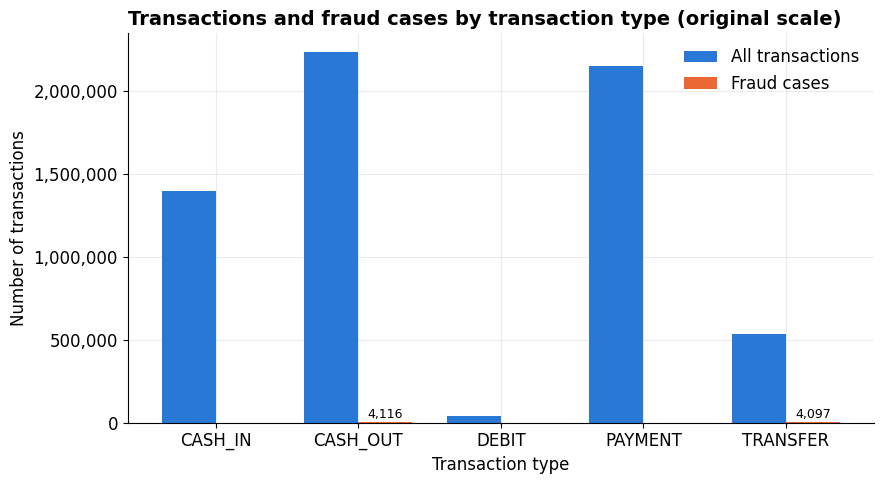

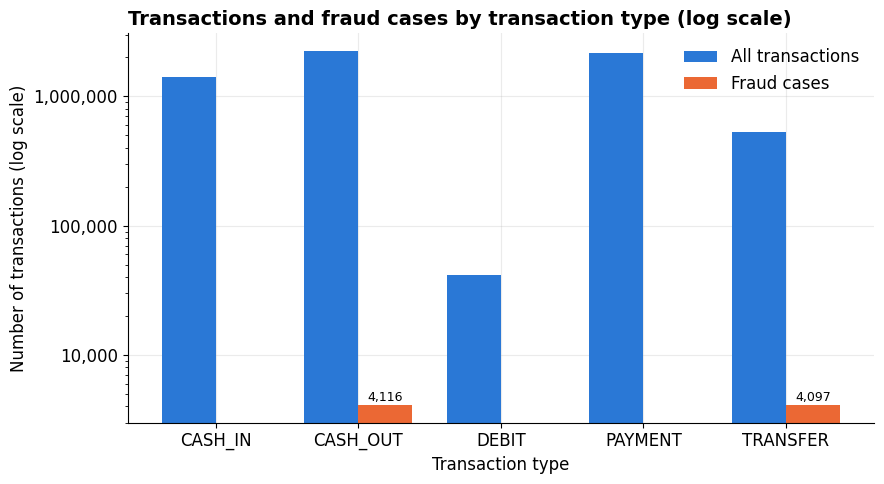

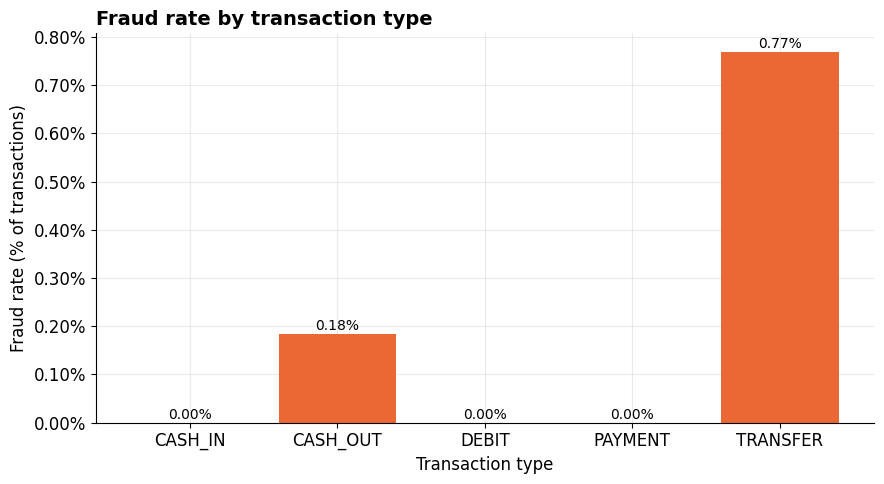

In [8]:
# ===== [Q2.2] Which transaction types carry fraud? =====
# PaySim has no channel field: transaction type is the channel, destination account class (C customer / M merchant) is the second proxy.
by_type = segment_table(df, "type")
show(by_type, "Q2_2_fraud_by_type")
by_dest = segment_table(df, "dest_class")
show(by_dest, "Q2_2_fraud_by_destination_class")
print("Merchant destinations (M) occur only with PAYMENT:", bool((df.loc[df["dest_class"] == "M", "type"] == "PAYMENT").all()),
      "-> destination class adds no information beyond transaction type.")

def draw_type_counts(ax, log):
    x, w = np.arange(len(by_type)), 0.38
    ax.bar(x - w / 2, by_type["transactions"], w, color=BLUE, label="All transactions")
    ax.bar(x + w / 2, by_type["fraud_cases"], w, color=ORANGE, label="Fraud cases")
    ax.set_xticks(x); ax.set_xticklabels(by_type.index.astype(str))
    for xi, c in zip(x + w / 2, by_type["fraud_cases"]):
        if c > 0: ax.annotate(f"{c:,.0f}", (xi, c), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)

# >>> SCALED PAIR: F04a = original values, F04b = log scale (y-axis) <<<
scaled_pair("F04", "transactions_and_fraud_by_type", "Transactions and fraud cases by transaction type", draw_type_counts,
            xlabel="Transaction type", ylabel="Number of transactions", log_axis="y", yfmt="plain", legend=True)
bar_chart("F05", "fraud_rate_by_type", "Fraud rate by transaction type", by_type.index, by_type["fraud_rate_pct"],
          "Transaction type", "Fraud rate (% of transactions)", color=ORANGE, pct=True)

,transactions,fraud_cases,total_value,fraud_value,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct,fraud_value_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
hour,,,,,,,,,,
0,"27,111",358,"3,200,401,133.58","366,685,648.61",1.32%,1.19%,1.46%,11.46%,4.36%,3.04%
1,"9,018",372,"1,555,136,461.33","700,179,276.58",4.13%,3.73%,4.56%,45.02%,4.53%,5.81%
2,"2,007",326,"917,807,529.16","628,560,056.95",16.24%,14.69%,17.92%,68.48%,3.97%,5.21%
3,"1,241",274,"452,670,433.94","340,582,284.76",22.08%,19.86%,24.47%,75.24%,3.34%,2.82%
4,"1,641",366,"637,355,461.27","502,723,699.68",22.30%,20.36%,24.38%,78.88%,4.46%,4.17%
5,"3,420",358,"733,140,777.32","446,186,370.27",10.47%,9.49%,11.54%,60.86%,4.36%,3.70%
6,"8,988",328,"1,342,656,886.21","330,311,639.84",3.65%,3.28%,4.06%,24.60%,3.99%,2.74%
7,"26,915",368,"4,771,771,726.72","621,345,818.05",1.37%,1.24%,1.51%,13.02%,4.48%,5.15%
8,"283,518",341,"57,230,312,371.27","413,074,885.38",0.12%,0.11%,0.13%,0.72%,4.15%,3.43%


,steps_observed,transactions,fraud_cases,total_value,fraud_value,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct,fraud_value_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
day,,,,,,,,,,,
1,24,"574,255",271,"92,131,865,625.65","211,163,827.46",0.05%,0.04%,0.05%,0.23%,3.30%,1.75%
2,24,"455,238",309,"71,238,642,397.16","379,239,685.07",0.07%,0.06%,0.08%,0.53%,3.76%,3.15%
3,24,"1,070",310,"447,084,472.63","394,508,860.60",28.97%,26.33%,31.76%,88.24%,3.77%,3.27%
4,24,"28,240",262,"3,830,547,360.59","438,246,816.02",0.93%,0.82%,1.05%,11.44%,3.19%,3.63%
5,24,"9,789",252,"1,325,133,839.05","244,980,578.12",2.57%,2.28%,2.91%,18.49%,3.07%,2.03%
6,24,"441,005",228,"73,409,986,368.34","367,233,582.40",0.05%,0.05%,0.06%,0.50%,2.78%,3.05%
7,24,"420,583",272,"67,070,777,584.77","401,790,128.80",0.06%,0.06%,0.07%,0.60%,3.31%,3.33%
8,24,"449,637",278,"70,030,598,500.48","351,994,017.01",0.06%,0.05%,0.07%,0.50%,3.38%,2.92%
9,24,"417,919",255,"58,067,765,398.42","384,571,254.76",0.06%,0.05%,0.07%,0.66%,3.10%,3.19%


,transactions,fraud_cases,total_value,fraud_value,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct,fraud_value_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
week,,,,,,,,,,
1,"1,930,180","1,904","309,454,037,648.19","2,437,163,478.47",0.10%,0.09%,0.10%,0.79%,23.18%,20.21%
2,"2,854,595","1,863","550,316,304,648.61","2,656,088,323.61",0.07%,0.06%,0.07%,0.48%,22.68%,22.03%
3,"1,279,261","1,854","233,698,261,514.92","3,033,818,536.24",0.14%,0.14%,0.15%,1.30%,22.57%,25.16%
4,"232,135","1,792","39,122,717,854.97","2,482,309,550.51",0.77%,0.74%,0.81%,6.34%,21.82%,20.59%
5,"66,449",800,"11,801,623,093.08","1,447,035,539.01",1.20%,1.12%,1.29%,12.26%,9.74%,12.00%


,spearman_daily_volume_vs_fraud_cases,cv_of_daily_fraud_cases,mean_fraud_cases_per_step,cv_of_fraud_cases_per_step,lowest_daily_fraud_rate_pct,highest_daily_fraud_rate_pct
value,-0.0343,0.0886,11.0538,0.4522,0.05%,100.00%


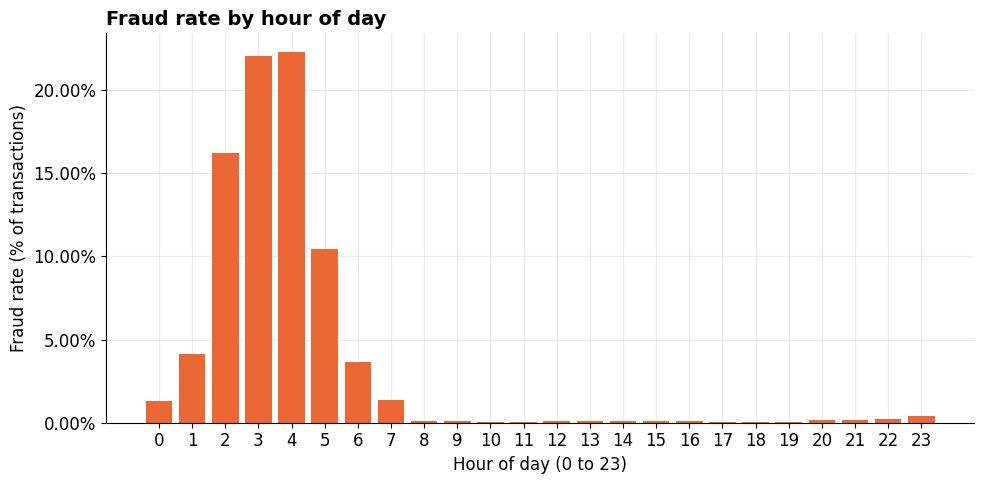

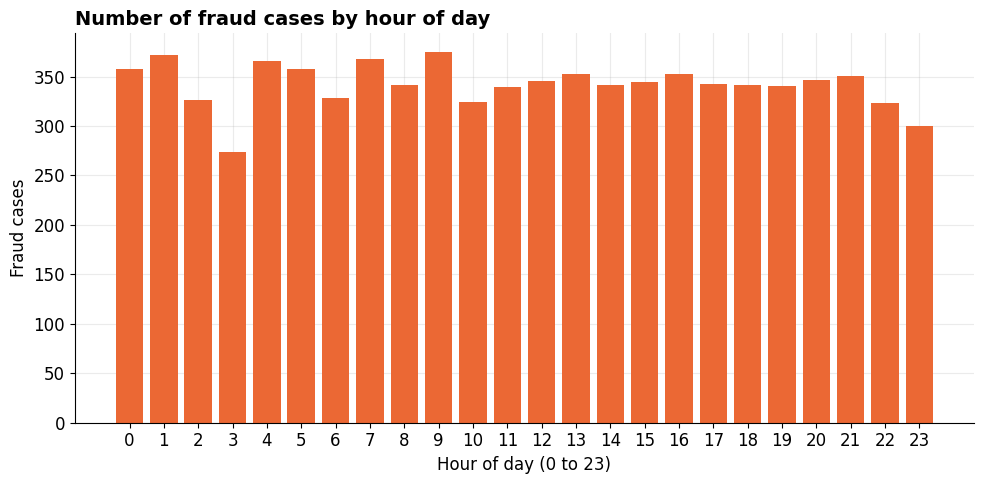

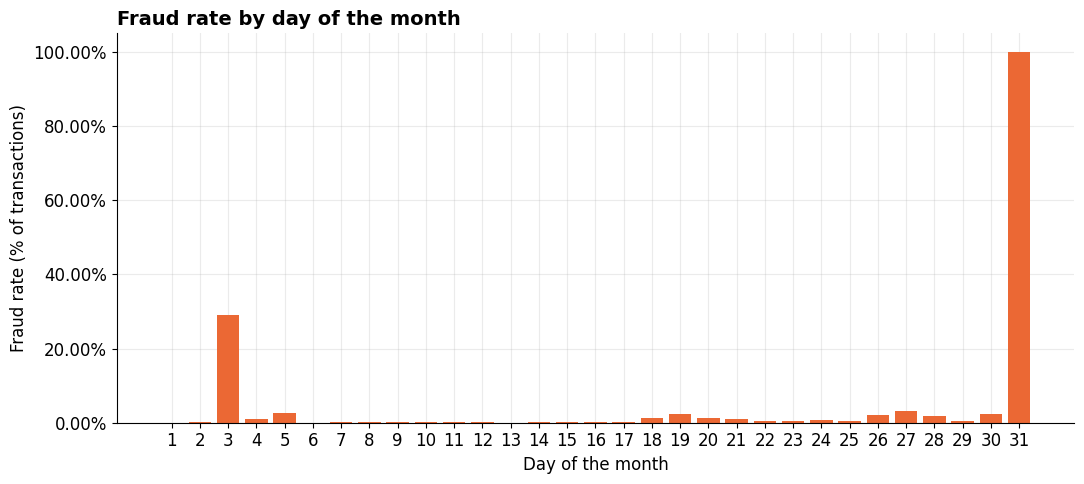

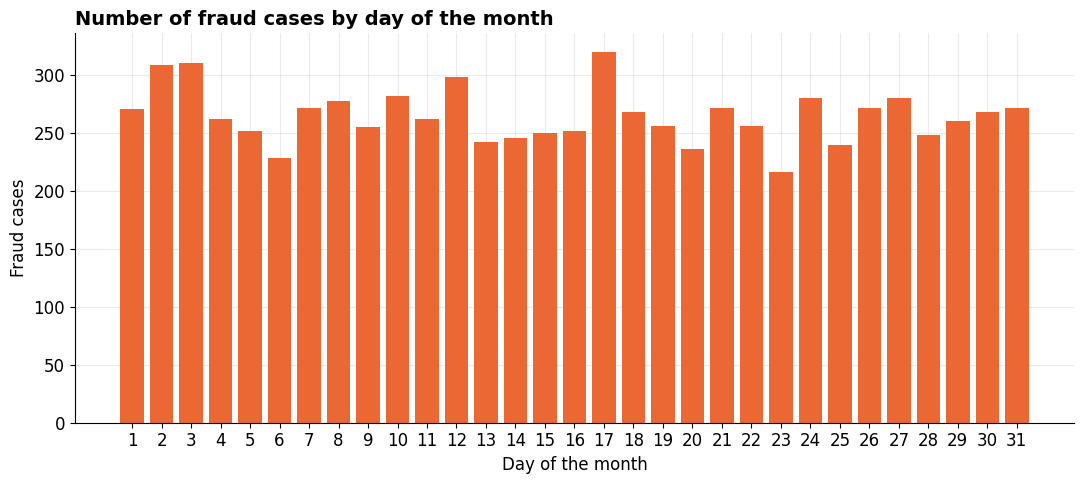

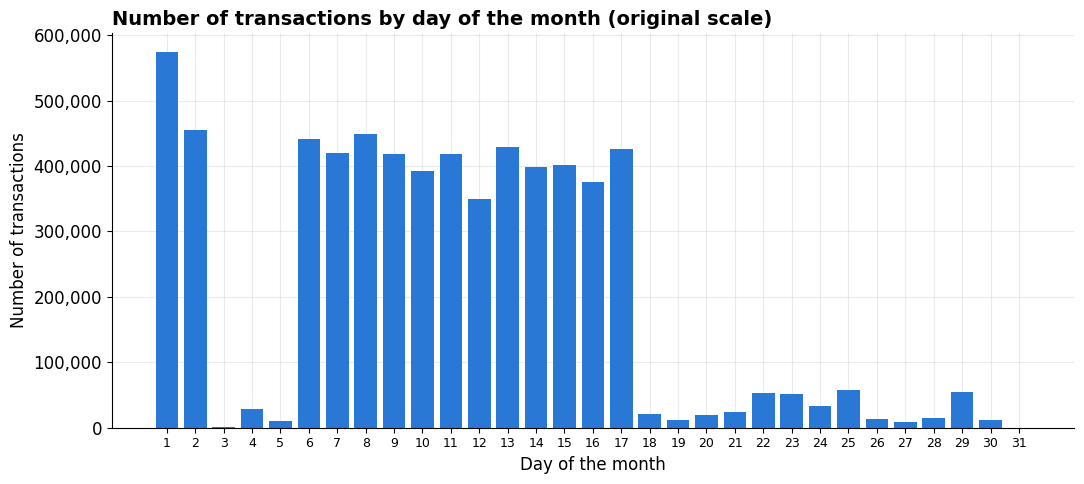

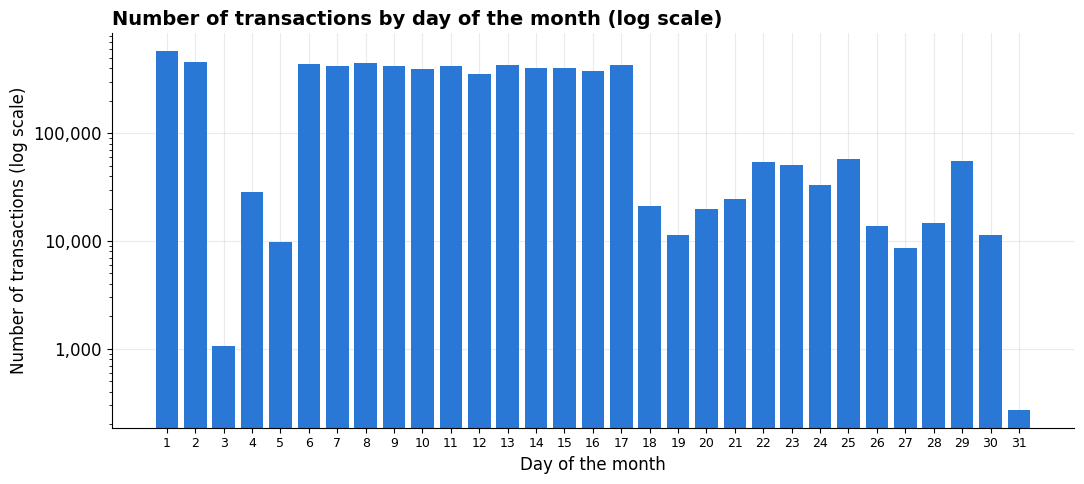

In [9]:
# ===== [Q2.3] How do fraud counts and rates vary by hour of day, and are rate differences driven by fraud or by volume? =====
by_hour, by_day, by_week = (segment_table(df, c) for c in ("hour", "day", "week"))
by_day.insert(0, "steps_observed", df.groupby("day")["step"].nunique())      # the last day is partial
show(by_hour, "Q2_3_fraud_by_hour"); show(by_day, "Q2_3_fraud_by_day"); show(by_week, "Q2_3_fraud_by_week")

per_step = df.groupby("step")["isFraud"].agg(["size", "sum"])
time_diag = pd.DataFrame({
    "spearman_daily_volume_vs_fraud_cases": [by_day[["transactions", "fraud_cases"]].corr(method="spearman").iloc[0, 1]],
    "cv_of_daily_fraud_cases": [sdiv(by_day["fraud_cases"].std(), by_day["fraud_cases"].mean())],
    "mean_fraud_cases_per_step": [per_step["sum"].mean()], "cv_of_fraud_cases_per_step": [sdiv(per_step["sum"].std(), per_step["sum"].mean())],
    "lowest_daily_fraud_rate_pct": [by_day["fraud_rate_pct"].min()], "highest_daily_fraud_rate_pct": [by_day["fraud_rate_pct"].max()]}, index=["value"])
show(time_diag, "Q2_3_time_window_diagnostics", decimals=4)

hours = [str(h) for h in by_hour.index]; days = [str(d) for d in by_day.index]
bar_chart("F06", "fraud_rate_by_hour", "Fraud rate by hour of day", hours, by_hour["fraud_rate_pct"], "Hour of day (0 to 23)",
          "Fraud rate (% of transactions)", color=ORANGE, pct=True, annotate=False, figsize=(10, 5))
bar_chart("F07", "fraud_cases_by_hour", "Number of fraud cases by hour of day", hours, by_hour["fraud_cases"], "Hour of day (0 to 23)",
          "Fraud cases", color=ORANGE, annotate=False, figsize=(10, 5))
bar_chart("F08", "fraud_rate_by_day", "Fraud rate by day of the month", days, by_day["fraud_rate_pct"], "Day of the month",
          "Fraud rate (% of transactions)", color=ORANGE, pct=True, annotate=False, figsize=(11, 5))
bar_chart("F09", "fraud_cases_by_day", "Number of fraud cases by day of the month", days, by_day["fraud_cases"], "Day of the month",
          "Fraud cases", color=ORANGE, annotate=False, figsize=(11, 5))

def draw_daily_volume(ax, log):
    ax.bar(days, by_day["transactions"], color=BLUE); plt.setp(ax.get_xticklabels(), fontsize=9)

# >>> SCALED PAIR: F10a = original values, F10b = log scale (y-axis) <<<
scaled_pair("F10", "transactions_per_day", "Number of transactions by day of the month", draw_daily_volume,
            xlabel="Day of the month", ylabel="Number of transactions", log_axis="y", yfmt="plain", figsize=(11, 5))

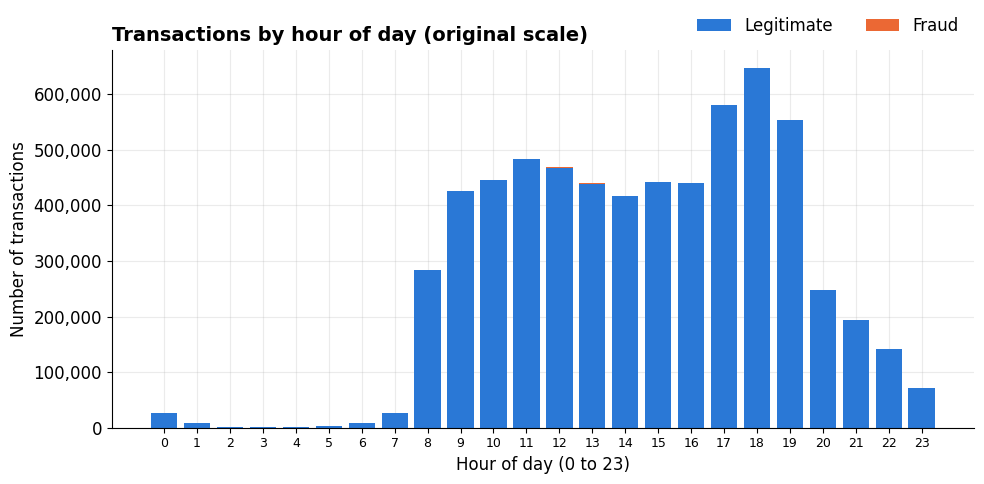

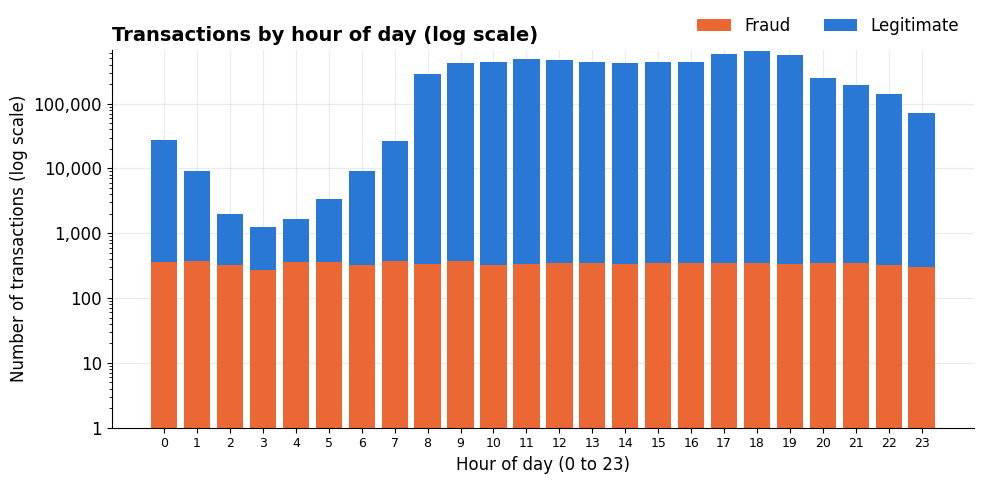

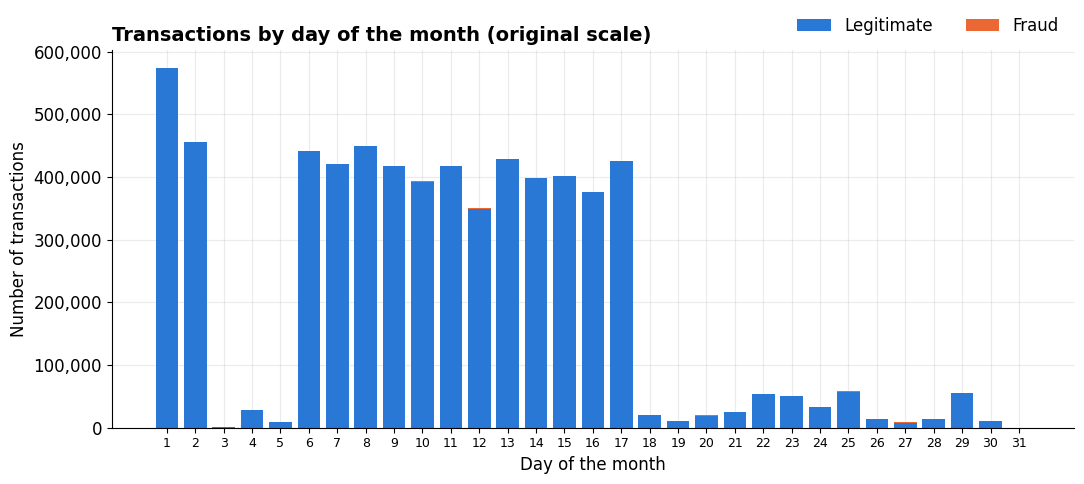

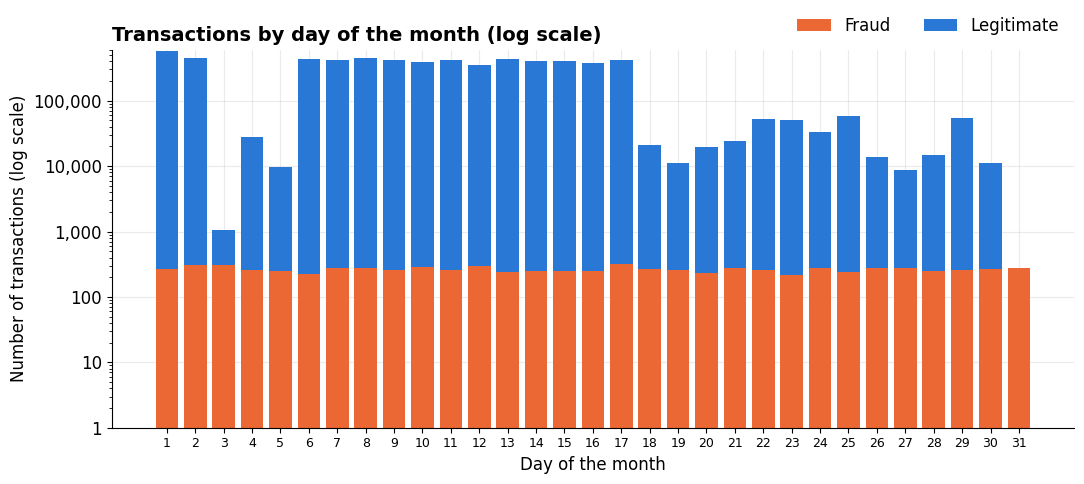

In [10]:
# ===== ADDITIONAL: Stacked bar charts - legitimate vs fraud transactions per hour of day and per day of month =====
def make_stacked_draw(tbl):
    """Return a draw(ax, log) function for scaled_pair: one bar per segment, split into legitimate and fraud."""
    labels = [str(i) for i in tbl.index]
    fraud = tbl["fraud_cases"].to_numpy()
    legit = (tbl["transactions"] - tbl["fraud_cases"]).to_numpy()   

    def draw(ax, log):
        if log:
            ax.bar(labels, fraud, color=ORANGE, label="Fraud")
            ax.bar(labels, legit, bottom=fraud, color=BLUE, label="Legitimate")
            ax.set_ylim(bottom=1)
        else:
            ax.bar(labels, legit, color=BLUE, label="Legitimate")
            ax.bar(labels, fraud, bottom=legit, color=ORANGE, label="Fraud")
        ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1.0, 1.0))
        plt.setp(ax.get_xticklabels(), fontsize=9)
    return draw

# >>> SCALED PAIRS: F11a/F12a = original values, F11b/F12b = log scale (y-axis) <<<
scaled_pair("F11", "stacked_transactions_by_hour", "Transactions by hour of day", make_stacked_draw(by_hour),
            xlabel="Hour of day (0 to 23)", ylabel="Number of transactions", log_axis="y", yfmt="plain", figsize=(10, 5))
scaled_pair("F12", "stacked_transactions_by_day", "Transactions by day of the month", make_stacked_draw(by_day),
            xlabel="Day of the month", ylabel="Number of transactions", log_axis="y", yfmt="plain", figsize=(11, 5))

## EQ3: Which patterns observable at initiation separate fraud from legitimate transactions?

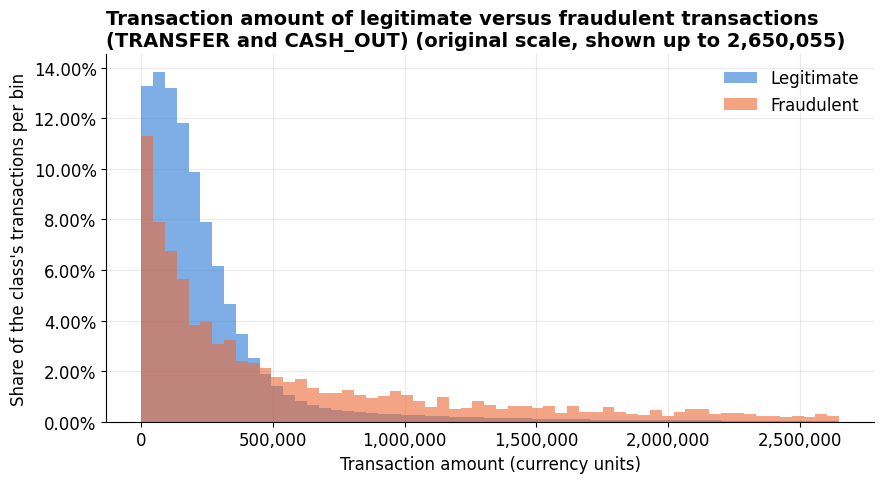

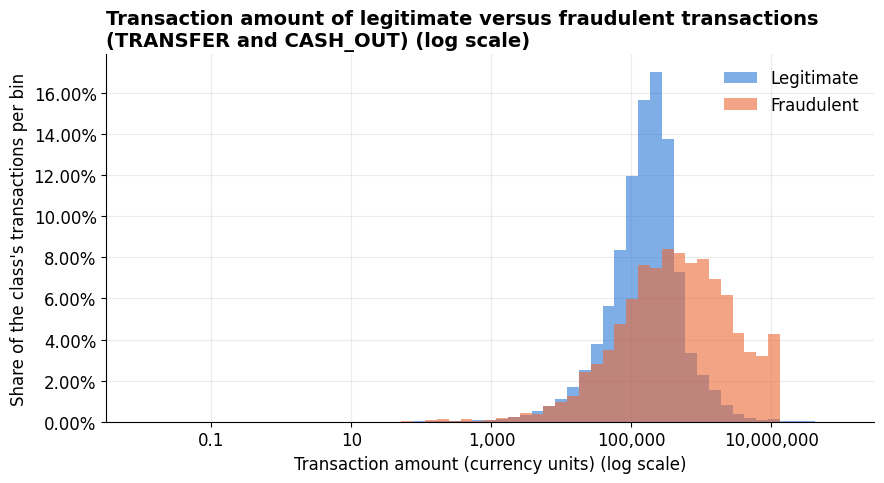

,transactions,fraud_cases,total_value,fraud_value,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct,fraud_value_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
amount_band,,,,,,,,,,
0 (zero amount),16,16,0.00,0.00,100.00%,80.64%,100.00%,,0.19%,0.00%
"above 0 to 1,000","7,785",42,"3,897,296.63","14,039.18",0.54%,0.40%,0.73%,0.36%,0.51%,0.00%
"1,000 to 10,000","71,044",220,"391,981,503.46","1,187,787.18",0.31%,0.27%,0.35%,0.30%,2.68%,0.01%
"10,000 to 50,000","332,168",760,"10,035,600,713.21","22,385,430.06",0.23%,0.21%,0.25%,0.22%,9.25%,0.19%
"50,000 to 100,000","425,099",669,"31,848,921,683.17","49,432,795.67",0.16%,0.15%,0.17%,0.16%,8.15%,0.41%
"100,000 to 200,000","736,628","1,035","108,654,415,334.70","149,852,781.59",0.14%,0.13%,0.15%,0.14%,12.60%,1.24%
"200,000 to 500,000","883,368","1,607","270,312,859,041.42","531,517,106.04",0.18%,0.17%,0.19%,0.20%,19.57%,4.41%
"500,000 to 1,000,000","183,794","1,158","124,838,048,743.83","841,303,179.17",0.63%,0.59%,0.67%,0.67%,14.10%,6.98%
"1,000,000 to 5,000,000","118,992","1,962","212,804,988,299.13","4,347,512,527.10",1.65%,1.58%,1.72%,2.04%,23.89%,36.06%


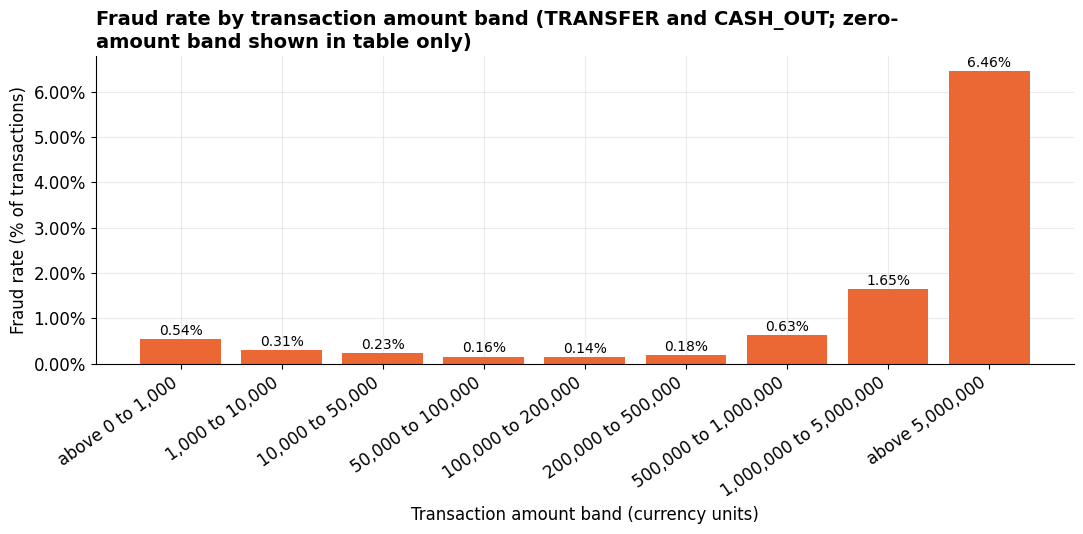

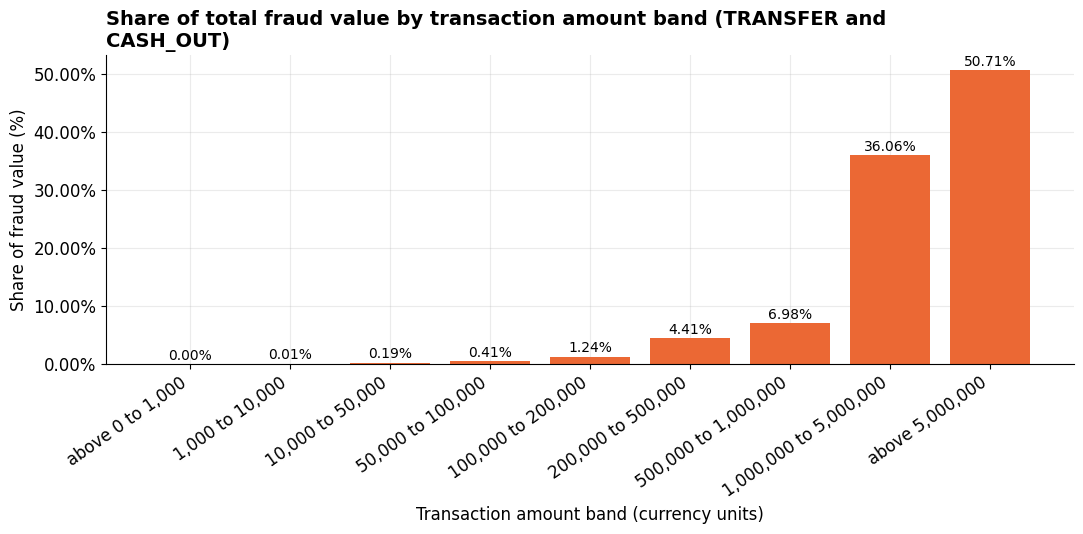

In [11]:
# ===== [Q3.1] How does fraud likelihood vary with amount? =====
leg = SC.loc[SC["isFraud"] == 0, "amount"].to_numpy(); fra = SC.loc[SC["isFraud"] == 1, "amount"].to_numpy()
leg_p, fra_p = leg[leg > 0], fra[fra > 0]; pool = np.concatenate([leg_p, fra_p])
clip2 = float(np.quantile(pool, P_CLIP)) if pool.size else 1.0

def draw_amount_by_class(ax, log):
    if not pool.size: return
    bins = np.logspace(np.log10(pool.min()), np.log10(pool.max()), 60) if log else np.linspace(0, clip2, 60)
    for x, c, lab in ((leg_p, BLUE, "Legitimate"), (fra_p, ORANGE, "Fraudulent")):
        if x.size: ax.hist(x, bins=bins, weights=np.full(x.size, 100 / x.size), alpha=.6, color=c, label=lab)

# >>> SCALED PAIR: F12a = original values (x-axis cut at the 99th percentile), F12b = log scale (x-axis) <<<
scaled_pair("F12", "amount_by_class", "Transaction amount of legitimate versus fraudulent transactions (TRANSFER and CASH_OUT)",
            draw_amount_by_class, xlabel="Transaction amount (currency units)", ylabel="Share of the class's transactions per bin",
            log_axis="x", xfmt="plain", yfmt="pct", legend=True, orig_note=f", shown up to {clip2:,.0f}")

EDGES = [-0.01, 0, 1_000, 10_000, 50_000, 100_000, 200_000, 500_000, 1_000_000, 5_000_000, np.inf]
BAND_LABELS = ["0 (zero amount)"] + [f"{lo:,.0f} to {hi:,.0f}" for lo, hi in zip(EDGES[1:-2], EDGES[2:-1])] + [f"above {EDGES[-2]:,.0f}"]
BAND_LABELS[1] = "above 0 to 1,000"          # bands are (lower, upper]
SC["amount_band"] = pd.cut(SC["amount"], EDGES, labels=BAND_LABELS)
bands = segment_table(SC, "amount_band")
show(bands, "Q3_1_fraud_by_amount_band")
bands_plot = bands.drop(index=BAND_LABELS[0], errors="ignore")      # the zero-amount band (few rows, 100% fraud) would flatten every other bar; it stays in the table
bar_chart("F13", "fraud_rate_by_amount_band", "Fraud rate by transaction amount band (TRANSFER and CASH_OUT; zero-amount band shown in table only)", bands_plot.index, bands_plot["fraud_rate_pct"],
          "Transaction amount band (currency units)", "Fraud rate (% of transactions)", color=ORANGE, pct=True, rotate=35, figsize=(11, 5.5))
bar_chart("F14", "fraud_value_share_by_amount_band", "Share of total fraud value by transaction amount band (TRANSFER and CASH_OUT)", bands_plot.index, bands_plot["share_of_fraud_value_pct"],
          "Transaction amount band (currency units)", "Share of fraud value (%)", color=ORANGE, pct=True, rotate=35, figsize=(11, 5.5))

,available_at_initiation,transactions_with_indicator,fraud_rate_with_pct,fraud_rate_without_pct,lift,share_of_fraud_with_indicator_pct
indicator,,,,,,
Destination account never seen before,yes,"391,463",1.32%,0.13%,10.35,63.00%
Origin account emptied by the transaction,no: balance field,"1,188,074",0.67%,0.01%,53.09,97.55%
Destination balance stays at 0,no: balance field,"5,776",70.46%,0.15%,470.21,49.56%
Origin balance identity fails,no: balance field,"2,500,051",0.00%,3.02%,0.00,0.55%
Destination balance identity fails,no: balance field,"628,237",0.74%,0.17%,4.43,56.50%


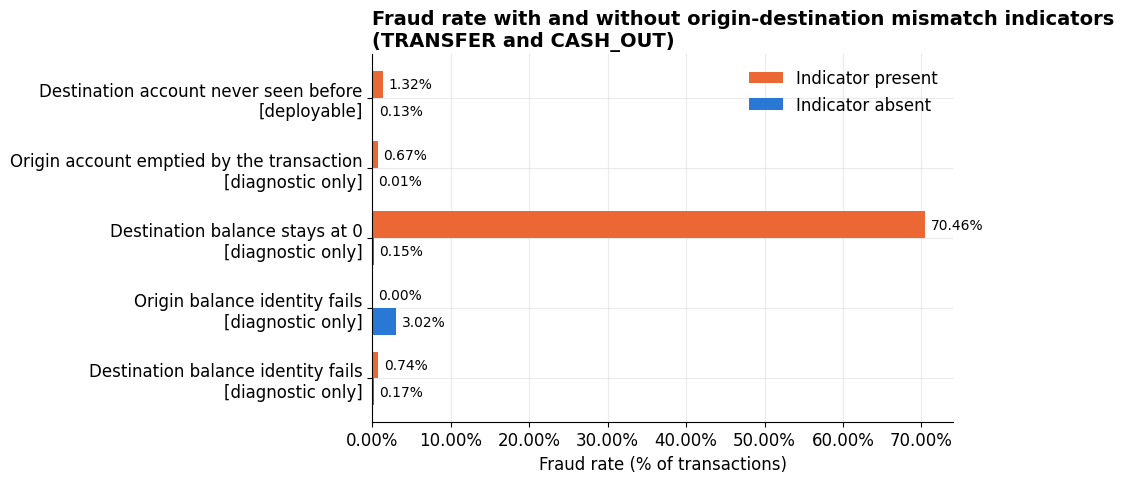

,transactions,fraud_cases,total_value,fraud_value,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct,fraud_value_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
dest_history,,,,,,,,,,
0 (first time seen),"391,463","5,174","115,422,847,482.85","7,776,290,631.02",1.32%,1.29%,1.36%,6.74%,63.00%,64.50%
1,"300,301",576,"78,021,243,336.10","801,610,916.73",0.19%,0.18%,0.21%,1.03%,7.01%,6.65%
2 to 4,"639,808",981,"171,374,850,333.19","1,350,053,018.33",0.15%,0.14%,0.16%,0.79%,11.94%,11.20%
5 to 19,"1,165,067","1,232","377,412,456,074.11","1,731,371,102.06",0.11%,0.10%,0.11%,0.46%,15.00%,14.36%
20 or more,"273,770",250,"137,473,585,261.41","397,089,759.70",0.09%,0.08%,0.10%,0.29%,3.04%,3.29%


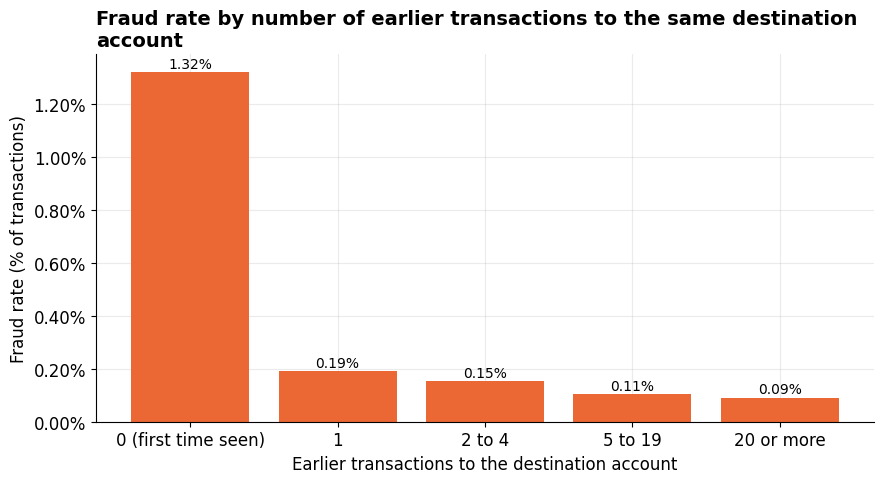

In [12]:
# ===== [Q3.2] Do origin-destination mismatch separate classes, and which are deployable? =====
INDICATORS = {   # label -> (column in SC, available at initiation?)
    "Destination account never seen before": ("dest_first_seen", "yes"),
    "Origin account emptied by the transaction": ("orig_emptied", "no: balance field"),
    "Destination balance stays at 0": ("dest_unchanged_zero", "no: balance field"),
    "Origin balance identity fails": ("orig_identity_fails", "no: balance field"),
    "Destination balance identity fails": ("dest_identity_fails", "no: balance field")}
fr = SC["isFraud"].to_numpy(); mm_rows = []
for label, (col, ok) in INDICATORS.items():
    m = SC[col].to_numpy().astype(bool); r1 = 100 * sdiv(fr[m].sum(), m.sum()); r0 = 100 * sdiv(fr[~m].sum(), (~m).sum())
    mm_rows.append({"indicator": label, "available_at_initiation": ok, "transactions_with_indicator": int(m.sum()),
                    "fraud_rate_with_pct": r1, "fraud_rate_without_pct": r0, "lift": sdiv(r1, r0),
                    "share_of_fraud_with_indicator_pct": 100 * sdiv(fr[m].sum(), fr.sum())})
mismatch = pd.DataFrame(mm_rows).set_index("indicator")
show(mismatch, "Q3_2_mismatch_indicators")

fig, ax = plt.subplots(figsize=(10, 5)); yy = np.arange(len(mismatch)); h = 0.38
ax.barh(yy - h / 2, mismatch["fraud_rate_with_pct"], h, color=ORANGE, label="Indicator present")
ax.barh(yy + h / 2, mismatch["fraud_rate_without_pct"], h, color=BLUE, label="Indicator absent")
for i, (a, b) in enumerate(zip(mismatch["fraud_rate_with_pct"], mismatch["fraud_rate_without_pct"])):
    ax.annotate(f"{a:,.2f}%", (a, i - h / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=10)
    ax.annotate(f"{b:,.2f}%", (b, i + h / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=10)
ax.set_yticks(yy); ax.set_yticklabels([f"{k}\n[{'deployable' if v == 'yes' else 'diagnostic only'}]" for k, v in zip(mismatch.index, mismatch["available_at_initiation"])]); ax.invert_yaxis()
finish(fig, ax, "F15", "fraud_rate_by_mismatch_indicator", "Fraud rate with and without origin-destination mismatch indicators (TRANSFER and CASH_OUT)",
       xlabel="Fraud rate (% of transactions)", xfmt="pct", legend=True)

SC["dest_history"] = pd.cut(SC["prior_dest"], [-1, 0, 1, 4, 19, np.inf], labels=["0 (first time seen)", "1", "2 to 4", "5 to 19", "20 or more"])
dest_hist = segment_table(SC, "dest_history")
show(dest_hist, "Q3_2_fraud_by_destination_history")
bar_chart("F16", "fraud_rate_by_destination_history", "Fraud rate by number of earlier transactions to the same destination account",
          dest_hist.index, dest_hist["fraud_rate_pct"], "Earlier transactions to the destination account",
          "Fraud rate (% of transactions)", color=ORANGE, pct=True)

In [13]:
# ===== [Q3.3] Do accounts recur enough for history features, and how concentrated is fraud on destination accounts? =====
def recurrence(c):
    return {"distinct_accounts": int(c.size), "single_use_accounts_pct": 100 * sdiv((c == 1).sum(), c.size),
            "max_rows_per_account": int(c.max()) if c.size else 0, "rows_from_recurring_accounts_pct": 100 * sdiv(c[c > 1].sum(), c.sum())}
recurrence_tab = pd.DataFrame.from_dict({"nameOrig (sender)": recurrence(orig_counts), "nameDest (customer recipients only)": recurrence(cust_dest_counts)}, orient="index")
show(recurrence_tab, "Q3_3_account_recurrence")
show(chain, "Q3_3_transfer_then_cash_out_chain")                       # computed in [Q1.1]

ds = DEST[SC.index.to_numpy()]; ysc = SC["isFraud"].to_numpy() == 1    # destination code of every in-scope row
cnt_all = np.bincount(ds); cnt_fraud = np.bincount(ds[ysc], minlength=cnt_all.size); is_fd = cnt_fraud > 0
fd_tab = pd.DataFrame({
    "distinct_fraud_destinations": [int(is_fd.sum())], "fraud_cases": [int(cnt_fraud.sum())],
    "fraud_destinations_with_one_fraud_pct": [100 * float((cnt_fraud[is_fd] == 1).mean())],
    "max_fraud_cases_per_destination": [int(cnt_fraud.max())],
    "fraud_cases_on_repeat_destinations_pct": [100 * sdiv(cnt_fraud[is_fd & (cnt_fraud > 1)].sum(), cnt_fraud.sum())],
    "fraud_destinations_also_receiving_legitimate_pct": [100 * float((cnt_all[is_fd] > cnt_fraud[is_fd]).mean())]}, index=["TRANSFER + CASH_OUT"])
show(fd_tab, "Q3_3_fraud_concentration_by_destination", transpose=True)

dp = SC["dest_prior_fraud"].to_numpy()          # label assumed known immediately: an upper bound of what a delayed label feed would give
pf = pd.DataFrame({"transactions": [int(dp.sum()), int((~dp).sum())], "fraud_cases": [int(ysc[dp].sum()), int(ysc[~dp].sum())]},
                  index=["destination received fraud in an earlier row", "no earlier fraud to the destination"])
pf["fraud_rate_pct"] = 100 * sdiv(pf["fraud_cases"], pf["transactions"])
pf["share_of_fraud_cases_pct"] = 100 * sdiv(pf["fraud_cases"], pf["fraud_cases"].sum())
show(pf, "Q3_3_destination_prior_fraud")

win = SC["window"].astype(str).to_numpy()
seen_tr = np.zeros(cnt_all.size, dtype=bool); seen_tr[ds[win == "train"]] = True
fraud_tr = np.zeros(cnt_all.size, dtype=bool); fraud_tr[ds[(win == "train") & ysc]] = True
def _share(flags, mask):
    return 100 * float(flags[ds[mask]].mean()) if mask.any() else np.nan
ov = [{"window": w, "rows_with_destination_seen_in_train_pct": _share(seen_tr, win == w),
       "fraud_rows_with_destination_seen_in_train_pct": _share(seen_tr, (win == w) & ysc),
       "fraud_rows_with_destination_fraud_in_train_pct": _share(fraud_tr, (win == w) & ysc)} for w in ["validation", "test"]]
show(pd.DataFrame(ov).set_index("window"), "Q3_3_destination_overlap_with_train")

,distinct_accounts,single_use_accounts_pct,max_rows_per_account,rows_from_recurring_accounts_pct
nameOrig (sender),"6,353,307",99.85%,3,0.29%
nameDest (customer recipients only),"571,961",19.83%,113,97.31%


,fraudulent_transfers,destination_cashes_out_at_or_after_the_transfer_step,share_pct
transfer-then-cash-out chain,"4,097",1,0.02%


,TRANSFER + CASH_OUT
distinct_fraud_destinations,"8,169"
fraud_cases,"8,213"
fraud_destinations_with_one_fraud_pct,99.46%
max_fraud_cases_per_destination,2
fraud_cases_on_repeat_destinations_pct,1.07%
fraud_destinations_also_receiving_legitimate_pct,61.97%


,transactions,fraud_cases,fraud_rate_pct,share_of_fraud_cases_pct
destination received fraud in an earlier row,"23,847",44,0.18%,0.54%
no earlier fraud to the destination,"2,746,562","8,169",0.30%,99.46%


,rows_with_destination_seen_in_train_pct,fraud_rows_with_destination_seen_in_train_pct,fraud_rows_with_destination_fraud_in_train_pct
window,,,
validation,78.77%,33.23%,0.55%
test,74.13%,30.80%,0.60%


ordering check, prior-destination count reproduces SC['prior_dest']: False


,transactions,fraud_cases,total_value,fraud_value,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct,fraud_value_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
dest_recv_band,,,,,,,,,,
0 (nothing before),"509,567","5,509","149,305,707,727.73","8,226,189,440.92",1.08%,1.05%,1.11%,5.51%,67.08%,68.23%
up to 10k,"11,646",29,"3,268,378,596.33","41,664,583.70",0.25%,0.17%,0.36%,1.27%,0.35%,0.35%
10k to 100k,"120,711",260,"29,479,786,925.64","329,958,252.30",0.22%,0.19%,0.24%,1.12%,3.17%,2.74%
100k to 1M,"978,424","1,361","226,261,079,290.02","1,992,234,642.07",0.14%,0.13%,0.15%,0.88%,16.57%,16.52%
1M to 10M,"1,098,581","1,000","393,041,460,142.34","1,367,453,631.06",0.09%,0.09%,0.10%,0.35%,12.18%,11.34%
over 10M,"51,480",54,"78,348,569,805.60","98,914,877.79",0.10%,0.08%,0.14%,0.13%,0.66%,0.82%


,transactions,fraud_cases,total_value,fraud_value,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct,fraud_value_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct
dest_recv_fraud_band,,,,,,,,,,
0 (nothing before),"2,746,576","8,169","870,620,241,786.24","12,019,812,508.44",0.30%,0.29%,0.30%,1.38%,99.46%,99.70%
up to 10k,994,1,"290,084,981.44",170.00,0.10%,0.02%,0.57%,0.00%,0.01%,0.00%
10k to 100k,"4,762",9,"1,452,983,871.50","4,039,532.79",0.19%,0.10%,0.36%,0.28%,0.11%,0.03%
100k to 1M,"10,108",24,"3,527,377,406.13","23,190,006.04",0.24%,0.16%,0.35%,0.66%,0.29%,0.19%
1M to 10M,"7,969",10,"3,814,294,442.35","9,373,210.57",0.13%,0.07%,0.23%,0.25%,0.12%,0.08%


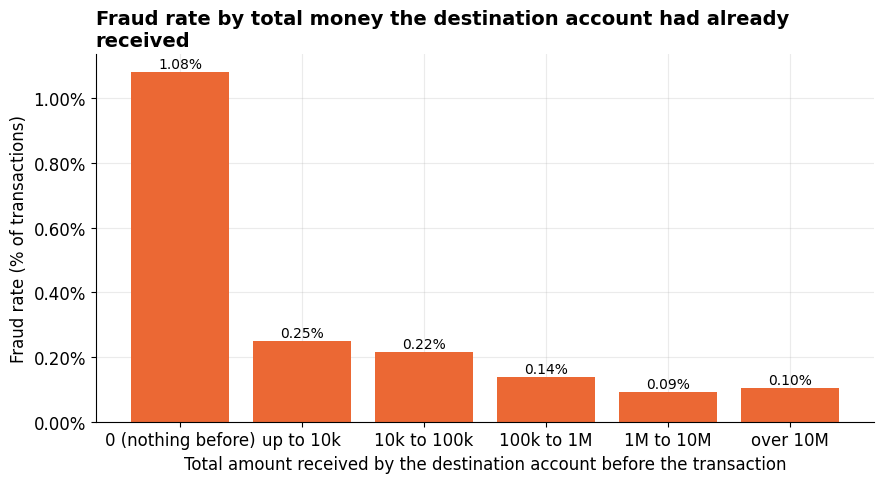

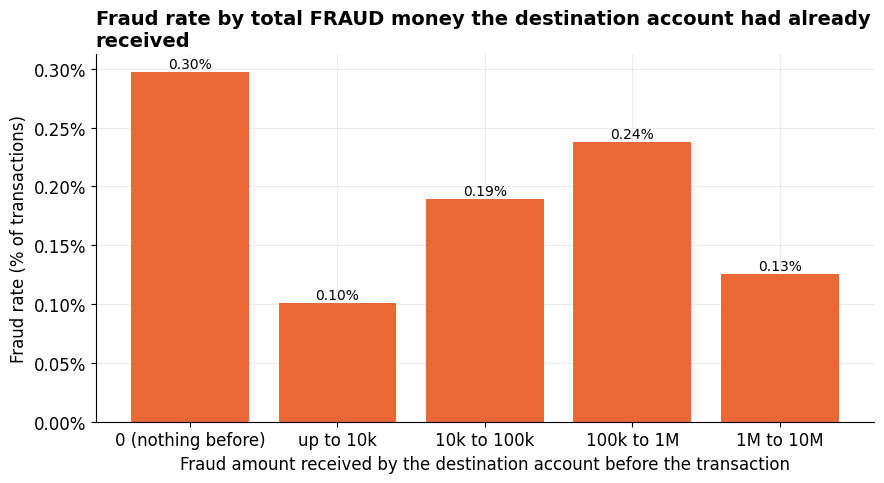

,TRANSFER + CASH_OUT
distinct_fraud_destinations,"8,169"
total_fraud_value,"12,056,415,427.84"
median_fraud_value_per_destination,"443,682.96"
max_fraud_value_per_destination,"10,160,088.68"
destinations_with_2plus_fraud_receipts_pct,0.54%
fraud_value_on_those_destinations_pct,0.69%
median_total_over_largest_single_receipt,1.17
destinations_whose_total_is_in_a_higher_band_than_their_largest_receipt_pct,0.06%
fraud_value_on_band_shifted_destinations_pct,0.04%


,share_of_total_fraud_value_pct
Top 1%,6.80%
Top 5%,32.89%
Top 10%,53.63%
Top 25%,79.98%
Top 50%,94.67%


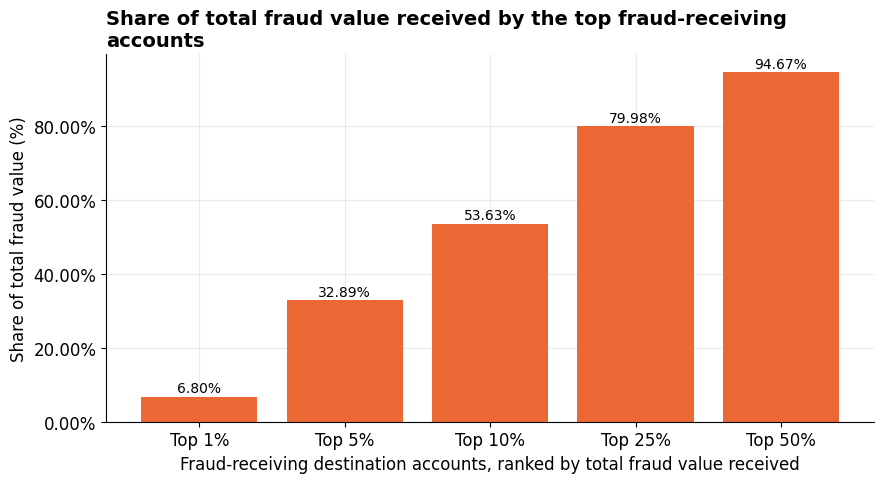

,transactions,fraud_cases,fraud_value,legit_value,fraud_rate_pct,share_transactions_pct,share_fraud_cases_pct,share_fraud_value_pct,share_legit_value_pct,fraud_value_cum_from_top_pct,legit_value_cum_from_top_pct
value_band,,,,,,,,,,,
under 1k,"7,801",58,"14,039.18","3,883,257.45",0.74%,0.28%,0.71%,0.00%,0.00%,100.00%,100.00%
1k to 10k,"71,040",220,"1,187,787.18","390,753,716.28",0.31%,2.56%,2.68%,0.01%,0.05%,100.00%,100.00%
10k to 100k,"757,271","1,429","71,818,225.73","41,812,744,170.65",0.19%,27.33%,17.40%,0.60%,4.82%,99.99%,99.95%
100k to 1M,"1,803,790","3,800","1,522,673,066.80","502,282,650,053.15",0.21%,65.11%,46.27%,12.63%,57.89%,99.39%,95.14%
1M to 10M,"124,857","2,419","7,590,722,308.95","245,821,613,485.69",1.94%,4.51%,29.45%,62.96%,28.33%,86.76%,37.25%
10M or more,"5,650",287,"2,870,000,000.00","77,336,922,376.60",5.08%,0.20%,3.49%,23.80%,8.91%,23.80%,8.91%


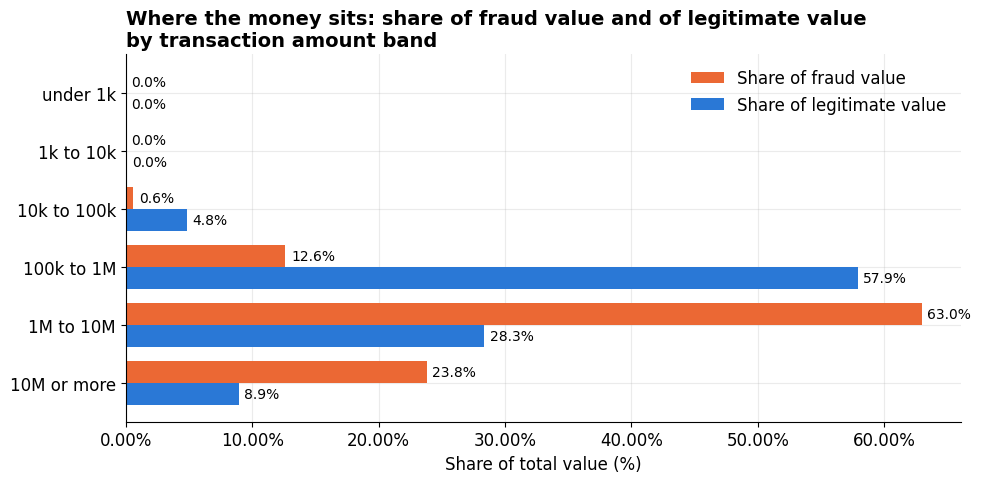

In [20]:
# ===== ADDITIONAL: Destination accounts in VALUE terms, where the fraud money sits =====
from scipy.stats import chi2_contingency, spearmanr
VAL_EDGES = [0, 1e3, 1e4, 1e5, 1e6, 1e7, np.inf]                                    # per-transaction amount bands ([low, high))
VAL_LABELS = ["under 1k", "1k to 10k", "10k to 100k", "100k to 1M", "1M to 10M", "10M or more"]
PRIOR_EDGES = [-1, 0, 1e4, 1e5, 1e6, 1e7, np.inf]                                   # money received before the row ((low, high])
PRIOR_LABELS = ["0 (nothing before)", "up to 10k", "10k to 100k", "100k to 1M", "1M to 10M", "over 10M"]

amt = SC["amount"].to_numpy(float); ysc = SC["isFraud"].to_numpy() == 1; ds = DEST[SC.index.to_numpy()]
# Rows are in time order, so (running total - own amount) = money the destination received BEFORE this row.
recv_all = pd.Series(amt).groupby(ds).cumsum().to_numpy() - amt                      # all money: deployable (needs no label)
recv_fraud = pd.Series(amt * ysc).groupby(ds).cumsum().to_numpy() - amt * ysc        # fraud money: assumes labels known at once (upper bound)
print("ordering check, prior-destination count reproduces SC['prior_dest']:",
      np.array_equal(pd.Series(ds).groupby(ds).cumcount().to_numpy(), SC["prior_dest"].to_numpy()))

# --- (1) F16 rewritten in value: fraud rate by money the destination had already received ---
SC["dest_recv_band"] = pd.cut(recv_all, PRIOR_EDGES, labels=PRIOR_LABELS)
SC["dest_recv_fraud_band"] = pd.cut(recv_fraud, PRIOR_EDGES, labels=PRIOR_LABELS)
recv_tab, recv_f_tab = segment_table(SC, "dest_recv_band"), segment_table(SC, "dest_recv_fraud_band")
show(recv_tab, "Q3_4_fraud_by_value_received_before"); show(recv_f_tab, "Q3_4_fraud_by_fraud_value_received_before")
bar_chart("F17", "fraud_rate_by_value_received_before", "Fraud rate by total money the destination account had already received",
          recv_tab.index, recv_tab["fraud_rate_pct"], "Total amount received by the destination account before the transaction",
          "Fraud rate (% of transactions)", color=ORANGE, pct=True)
bar_chart("F18", "fraud_rate_by_fraud_value_received_before", "Fraud rate by total FRAUD money the destination account had already received",
          recv_f_tab.index, recv_f_tab["fraud_rate_pct"], "Fraud amount received by the destination account before the transaction",
          "Fraud rate (% of transactions)", color=ORANGE, pct=True)

# --- (2) Per destination: many small fraud receipts add up, which a transaction count cannot show ---
pdst = pd.DataFrame({"dest": ds[ysc], "amount": amt[ysc]}).groupby("dest")["amount"].agg(
    fraud_cases="size", fraud_value="sum", largest_single="max")
b_tot = np.digitize(pdst["fraud_value"], VAL_EDGES[1:-1]); b_max = np.digitize(pdst["largest_single"], VAL_EDGES[1:-1])
up, multi, tot = b_tot > b_max, pdst["fraud_cases"] > 1, pdst["fraud_value"].sum()
r_tot = np.asarray(sdiv(pdst.loc[multi, "fraud_value"], pdst.loc[multi, "largest_single"]), float)   # total / largest receipt, 2+ receipts only
dest_val_tab = pd.DataFrame({
    "distinct_fraud_destinations": [len(pdst)], "total_fraud_value": [tot],
    "median_fraud_value_per_destination": [pdst["fraud_value"].median()], "max_fraud_value_per_destination": [pdst["fraud_value"].max()],
    "destinations_with_2plus_fraud_receipts_pct": [100 * multi.mean()],
    "fraud_value_on_those_destinations_pct": [100 * sdiv(pdst.loc[multi, "fraud_value"].sum(), tot)],
    "median_total_over_largest_single_receipt": [float(np.nanmedian(r_tot)) if r_tot.size else np.nan],
    "destinations_whose_total_is_in_a_higher_band_than_their_largest_receipt_pct": [100 * up.mean()],
    "fraud_value_on_those_destinations_pct_2": [100 * sdiv(pdst.loc[up, "fraud_value"].sum(), tot)]}, index=["TRANSFER + CASH_OUT"])
dest_val_tab = dest_val_tab.rename(columns={"fraud_value_on_those_destinations_pct_2": "fraud_value_on_band_shifted_destinations_pct"})
show(dest_val_tab, "Q3_4_fraud_value_received_per_destination", transpose=True)

srt = np.sort(pdst["fraud_value"].to_numpy())[::-1]; cs = np.cumsum(srt) / srt.sum()
top_share = pd.Series({f"Top {p}%": 100 * cs[max(int(np.ceil(len(srt) * p / 100)) - 1, 0)] for p in (1, 5, 10, 25, 50)})
show(top_share.to_frame("share_of_total_fraud_value_pct"), "Q3_4_fraud_value_held_by_top_destinations")
bar_chart("F19", "fraud_value_share_of_top_destinations", "Share of total fraud value received by the top fraud-receiving accounts",
          top_share.index, top_share, "Fraud-receiving destination accounts, ranked by total fraud value received",
          "Share of total fraud value (%)", color=ORANGE, pct=True)

# --- (3) Do high-value bands hold most of the fraud value? Compare with where legitimate money sits (a skewed base alone gives high shares) ---
SC["value_band"] = pd.cut(amt, VAL_EDGES, labels=VAL_LABELS, right=False)
vb = SC.assign(_fv=amt * ysc, _lv=amt * ~ysc).groupby("value_band", observed=False).agg(
    transactions=("isFraud", "size"), fraud_cases=("isFraud", "sum"), fraud_value=("_fv", "sum"), legit_value=("_lv", "sum"))
vb["fraud_rate_pct"] = 100 * sdiv(vb["fraud_cases"], vb["transactions"])
for c in ("transactions", "fraud_cases", "fraud_value", "legit_value"):
    vb[f"share_{c}_pct"] = 100 * sdiv(vb[c], vb[c].sum())
vb["fraud_value_cum_from_top_pct"] = vb["share_fraud_value_pct"][::-1].cumsum()[::-1]
vb["legit_value_cum_from_top_pct"] = vb["share_legit_value_pct"][::-1].cumsum()[::-1]
show(vb, "Q3_4_value_by_amount_band")

fig, ax = plt.subplots(figsize=(10, 5)); yy = np.arange(len(vb)); h = 0.38
ax.barh(yy - h / 2, vb["share_fraud_value_pct"], h, color=ORANGE, label="Share of fraud value")
ax.barh(yy + h / 2, vb["share_legit_value_pct"], h, color=BLUE, label="Share of legitimate value")
for i, (a, b) in enumerate(zip(vb["share_fraud_value_pct"], vb["share_legit_value_pct"])):
    ax.annotate(f"{a:,.1f}%", (a, i - h / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=10)
    ax.annotate(f"{b:,.1f}%", (b, i + h / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=10)
ax.set_yticks(yy); ax.set_yticklabels(vb.index.astype(str)); ax.invert_yaxis()
finish(fig, ax, "F20", "value_share_by_amount_band", "Where the money sits: share of fraud value and of legitimate value by transaction amount band",
       xlabel="Share of total value (%)", xfmt="pct", legend=True)

## EQ4: What do the current rule and simple benchmarks achieve on the business KPIs?

In [21]:
# ===== [Q4.0] EQ4 - Baseline policies and the amount-only threshold sweep =====
# Policies are decline-only (no manual-review queue exists in the data). The additional-cost terms are set to 0 (ADDITIONAL_COST), so
# Net fraud cost rate = (fraud value not stopped + 0) / TPV and Net financial loss avoided = fraud value stopped - 0.
_a = AMT[IN_SC]; _o = np.argsort(_a, kind="stable"); A_S, Y_S = _a[_o], Y[IN_SC][_o]       # in-scope amounts sorted ascending, with labels
CF_V, CL_V = np.array(np.r_[0, np.cumsum(A_S * Y_S)]), np.array(np.r_[0, np.cumsum(A_S * ~Y_S)])
CF_N, CL_N = np.array(np.r_[0, np.cumsum(Y_S)]), np.array(np.r_[0, np.cumsum(~Y_S)])

# Exact threshold: the LOWEST amount cut-off (decline if amount >= cut-off) whose declined legitimate value stays within the guardrail
_u = np.unique(A_S); _j = np.searchsorted(A_S, _u, side="left")
_ok = (CL_V[-1] - CL_V[_j]) <= FPR_GUARDRAIL * LEGIT_V
T_GUARD = float(_u[_ok][0]) if _ok.any() else np.inf

def sweep_table(thr):
    """Amount-only rule 'decline if amount >= threshold', evaluated at each threshold (TRANSFER + CASH_OUT only)."""
    thr = np.unique(np.asarray(thr, dtype=float)); i = np.searchsorted(A_S, thr, side="left")
    sw = pd.DataFrame({"threshold": thr, "alerts": len(A_S) - i, "true_positives": CF_N[-1] - CF_N[i], "false_positives": CL_N[-1] - CL_N[i],
                       "fraud_value_caught": CF_V[-1] - CF_V[i], "legit_value_declined": CL_V[-1] - CL_V[i]})
    sw["alerts_per_step"] = sw["alerts"] / N_STEPS_OBS
    sw["alert_precision_pct"] = 100 * sdiv(sw["true_positives"], sw["alerts"])
    sw["value_detection_rate_pct"] = 100 * sdiv(sw["fraud_value_caught"], TOTAL_FRAUD_V)
    sw["false_decline_rate_pct"] = 100 * sdiv(sw["false_positives"], LEGIT_N)
    sw["false_positive_rate_value_pct"] = 100 * sdiv(sw["legit_value_declined"], LEGIT_V)
    return sw
SW = sweep_table(np.r_[np.logspace(2, 8, 121), [FLAG_THRESHOLD] + ([T_GUARD] if np.isfinite(T_GUARD) else [])])

IS_TRANSFER = (df["type"] == "TRANSFER").to_numpy()
POL_NAMES = ["Do nothing (approve all)", "Current rule (isFlaggedFraud column)", f"Documented rule (TRANSFER above {FLAG_THRESHOLD:,})",
             f"Amount-only, within the {FPR_GUARDRAIL:.2%} guardrail"]
POLICIES = {POL_NAMES[0]: np.zeros(N, dtype=bool), POL_NAMES[1]: df["isFlaggedFraud"].to_numpy() == 1,
            POL_NAMES[2]: IS_TRANSFER & (AMT > FLAG_THRESHOLD), POL_NAMES[3]: IN_SC & (AMT >= T_GUARD)}

In [22]:
# ===== [Q4.1] Outcome: net fraud cost rate and net financial loss avoided =====
def kpi_row(d):
    tp, fp = int((d & Y).sum()), int((d & ~Y).sum()); alerts = tp + fp
    caught, fp_v = float(AMT[d & Y].sum()), float(AMT[d & ~Y].sum()); missed = TOTAL_FRAUD_V - caught
    return {"alerts": alerts, "alerts_per_step": alerts / N_STEPS_OBS, "true_positives": tp, "false_positives": fp,
            "alert_precision_pct": 100 * sdiv(tp, alerts),
            "value_weighted_detection_rate_pct": 100 * sdiv(caught, TOTAL_FRAUD_V), "count_detection_rate_pct": 100 * sdiv(tp, TOTAL_FRAUD_N),
            "false_decline_rate_pct": 100 * sdiv(fp, LEGIT_N), "false_positive_rate_value_pct": 100 * sdiv(fp_v, LEGIT_V),
            "fraud_value_stopped": caught, "legit_value_declined": fp_v,
            "net_fraud_cost_rate_pct": 100 * sdiv(missed + ADDITIONAL_COST, TPV),
            "net_financial_loss_avoided": caught - ADDITIONAL_COST}

kpi = pd.DataFrame.from_dict({n: kpi_row(d) for n, d in POLICIES.items()}, orient="index")
kpi.insert(0, "amount_threshold", [np.nan, np.nan, FLAG_THRESHOLD, T_GUARD])
kpi["within_fpr_guardrail"] = np.where(kpi["false_positive_rate_value_pct"] <= 100 * FPR_GUARDRAIL, "yes", "no")
print(f"Additional cost (lost fee/margin on false declines + review cost) = {ADDITIONAL_COST:,.0f}: not recorded in PaySim. "
      f"False-positive guardrail = {FPR_GUARDRAIL:.2%} of legitimate value.")
show(kpi, "Q4_1_kpi_by_policy", transpose=True)

Additional cost (lost fee/margin on false declines + review cost) = 0: not recorded in PaySim. False-positive guardrail = 1.51% of legitimate value.


,Do nothing (approve all),Current rule (isFlaggedFraud column),"Documented rule (TRANSFER above 200,000)","Amount-only, within the 1.51% guardrail"
amount_threshold,,,"200,000.00","26,457,619.96"
alerts,0,16,"409,110",463
alerts_per_step,0.00,0.02,550.62,0.62
true_positives,0,16,"2,740",0
false_positives,0,0,"406,370",463
alert_precision_pct,,100.00%,0.67%,0.00%
value_weighted_detection_rate_pct,0.00%,0.65%,49.40%,0.00%
count_detection_rate_pct,0.00%,0.19%,33.36%,0.00%
false_decline_rate_pct,0.00%,0.00%,6.40%,0.01%
false_positive_rate_value_pct,0.00%,0.00%,41.24%,1.51%


In [23]:
# ===== [Q4.2] Review load and raking quality: alert precision, alerts per step, Precision@k and PR-AUC =====
# Review load (alert precision, alerts per step) is in the [Q4.1] table. Ties at the 10,000,000 cap are broken by file order.
a_sc, y_sc = AMT[IN_SC], Y[IN_SC]; order = np.argsort(-a_sc, kind="stable"); a_top, y_top = a_sc[order], y_sc[order]
n_cur = int(POLICIES[POL_NAMES[1]].sum()); base_rate = float(y_sc.mean()) if len(y_sc) else np.nan
ks = sorted({min(k, len(y_top)) for k in [n_cur] + K_VALUES if k > 0 and len(y_top) > 0})      # k = 16 is the number of alerts of the current rule
pk = pd.DataFrame([{"k": k, "fraud_in_top_k": int(y_top[:k].sum()), "precision_at_k_pct": 100 * y_top[:k].mean(),
                    "fraud_value_in_top_k_share_pct": 100 * sdiv(a_top[:k][y_top[:k]].sum(), TOTAL_FRAUD_V),
                    "random_selection_precision_pct": 100 * base_rate, "lift_over_random": sdiv(y_top[:k].mean(), base_rate)} for k in ks],
                  columns=["k", "fraud_in_top_k", "precision_at_k_pct", "fraud_value_in_top_k_share_pct", "random_selection_precision_pct", "lift_over_random"]).set_index("k")
pk["current_rule_precision_pct"] = np.where(pk.index == n_cur, kpi.loc[POL_NAMES[1], "alert_precision_pct"], np.nan)   # only meaningful at k = alerts of the current rule
show(pk, "Q4_3_precision_at_k")

ap = float(average_precision_score(y_sc, a_sc)) if 0 < y_sc.sum() < len(y_sc) else np.nan
pr_tab = pd.DataFrame({"pr_auc_amount_only": [ap], "pr_auc_random_selection": [base_rate], "lift_over_random": [sdiv(ap, base_rate)]}, index=["TRANSFER + CASH_OUT"])
show(pr_tab, "Q4_3_pr_auc_amount_only", decimals=4)

,fraud_in_top_k,precision_at_k_pct,fraud_value_in_top_k_share_pct,random_selection_precision_pct,lift_over_random,current_rule_precision_pct
k,,,,,,
16,0,0.00%,0.00%,0.30%,0,100.00%
100,0,0.00%,0.00%,0.30%,0,
1000,0,0.00%,0.00%,0.30%,0,


,pr_auc_amount_only,pr_auc_random_selection,lift_over_random
TRANSFER + CASH_OUT,0.0194,0.0030,6.5424
